# Level 3 - Task 1: Time Series Analysis

Project Objective

The objective of this project is to analyse historical exchange-rate data, identify patterns over time, apply smoothing techniques, and build a time-series forecasting model.

The analysis will use the Central Bank of Nigeria (CBN) exchange-rate dataset prepared in Level 1. The project will cover time-series decomposition, moving averages, exponential smoothing, ARIMA or SARIMA forecasting, and model evaluation using RMSE.

In [1]:
from pathlib import Path

print("Current working directory:", Path.cwd())
print("\nFiles in the current directory:")

for file in Path.cwd().iterdir():
    print(file.name)

Current working directory: c:\Users\user\Downloads\Codeveda_Internship\Level_3_Data_Science_Applications

Files in the current directory:
cbn_exchange_rates_cleaned.csv
NLP_Text_Classification.ipynb
SMSSpamCollection
SMSSpamCollection_readme.txt
Time_Series_Analysis.ipynb


## 1. Dataset Loading and Initial Inspection

We will load the cleaned CBN exchange-rate dataset and inspect its structure before making any further changes. This helps us identify the available variables, confirm the data types, and understand what preparation is needed for time-series analysis.

In [2]:
# Import the libraries we'll use throughout the project
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the cleaned CBN exchange-rate dataset
df = pd.read_csv("cbn_exchange_rates_cleaned.csv")

# 1. Dataset structure
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

# 2. Preview the data
print("\nFirst five rows:")
display(df.head())

# 3. Data types and non-null counts
print("\nDataset information:")
df.info()

# 4. Missing values
print("\nMissing values per column:")
display(df.isnull().sum().to_frame("Missing Values"))

# 5. Duplicate rows
print("\nNumber of completely duplicated rows:", df.duplicated().sum())

# 6. Unique values in categorical columns
categorical_cols = df.select_dtypes(include=["object", "str"]).columns

print("\nUnique values in categorical columns:")
for col in categorical_cols:
    print(f"{col}: {df[col].nunique()} unique values")

Dataset shape: (62250, 6)

Column names:
['id', 'currency', 'ratedate', 'buyingrate', 'centralrate', 'sellingrate']

First five rows:


,id,currency,ratedate,buyingrate,centralrate,sellingrate
0,64143,CFA,2026-10-09,2.2508,2.2608,2.2708
1,64144,YUAN/RENMINBI,2026-10-09,198.7637,198.8384,198.9131
2,64145,DANISH KRONA,2026-10-09,199.2639,199.3388,199.4137
3,64146,EURO,2026-10-09,1489.6753,1490.2353,1490.7952
4,64147,YEN,2026-10-09,8.4024,8.4056,8.4087



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 62250 entries, 0 to 62249
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           62250 non-null  int64  
 1   currency     62250 non-null  str    
 2   ratedate     62250 non-null  str    
 3   buyingrate   62250 non-null  float64
 4   centralrate  62250 non-null  float64
 5   sellingrate  62250 non-null  float64
dtypes: float64(3), int64(1), str(2)
memory usage: 3.9 MB

Missing values per column:


,Missing Values
id,0
currency,0
ratedate,0
buyingrate,0
centralrate,0
sellingrate,0



Number of completely duplicated rows: 0

Unique values in categorical columns:
currency: 15 unique values
ratedate: 6095 unique values


Initial Data Inspection

The cleaned CBN exchange-rate dataset contains 62,250 observations and six columns. The dataset includes 15 currencies and 6,095 unique dates. No missing values or completely duplicated rows were detected during the initial inspection.

The ratedate column is currently stored as a string, so it must be converted to a datetime format. Since the dataset contains multiple currencies, the analysis will focus on the US dollar central exchange rate to create a single time series.

In [3]:
# Convert the date column to pandas datetime
df["ratedate"] = pd.to_datetime(df["ratedate"], errors="coerce")

# Check whether conversion introduced any invalid dates
print("Invalid dates:", df["ratedate"].isna().sum())
print("Date data type:", df["ratedate"].dtype)

# Check duplicate records while excluding the ID
duplicate_records = df.duplicated(subset=["currency", "ratedate", "buyingrate", "centralrate", "sellingrate"]).sum()

# Check for duplicate currency-date combinations, ignoring the ID
duplicate_observations = df.duplicated(
    subset=["currency", "ratedate"]
).sum()

print("Duplicate currency-date observations:", duplicate_observations)
print("Duplicate Records Excluding ID,", duplicate_records)

Invalid dates: 0
Date data type: datetime64[us]
Duplicate currency-date observations: 80
Duplicate Records Excluding ID, 0


In [4]:
# Inspect the currency names exactly as they appear in the dataset
print("Available currencies:")
print(sorted(df["currency"].unique()))

Available currencies:
['CFA', 'DANISH KRONA', 'EURO', 'NAIRA', 'POESO', 'POUNDS STERLING', 'RIYAL', 'SDR', 'SOUTH AFRICAN RAND', 'SWISS FRANC', 'UAE DIRHAM', 'US DOLLAR', 'WAUA', 'YEN', 'YUAN/RENMINBI']


<u>Date Conversion, Currency Labels, and Duplicate Checks</u>

Before preparing the dataset for time-series analysis, we carried out additional checks to understand its date format, currency labels, and record consistency.

Date conversion: The ratedate column was initially stored as a string. We converted it to pandas datetime using pd.to_datetime() so that the dates could be sorted chronologically, used as a time-based index, and plotted correctly during the analysis.

Invalid date check: We used errors="coerce" during conversion so that any date pandas could not interpret would be marked as NaT. We then counted these values to verify whether the conversion introduced any invalid or missing dates. The result was zero, meaning all dates converted successfully.

Currency label inspection: We displayed the sorted unique values in the currency column to identify the exact labels available in the dataset. This is necessary because we need to use the correct label when selecting a particular currency for analysis. The output confirmed that US DOLLAR is the label to use for the US dollar exchange-rate series.

Duplicate checks: The initial check found no completely duplicated rows. We then checked for duplicate records while excluding the id column and found zero. However, checking only the currency and date revealed 80 repeated currency-date observations. These are records in which a currency-date combination occurs more than once; they are not necessarily errors.

The duplicate findings will be investigated separately before any rows are removed. Once the dataset’s structure and currency labels are understood, we can select the US dollar central exchange rate and prepare it for time-series analysis.

In [5]:
# Select every row belonging to a repeated currency-date combination
duplicate_rows = df[
    df.duplicated(
        subset=["currency", "ratedate"],
        keep=False
    )
].sort_values(["currency", "ratedate"])

# Display all columns so we can compare the exchange rates and IDs
display(duplicate_rows)

,id,currency,ratedate,buyingrate,centralrate,sellingrate
7927,55057,CFA,2024-02-22,2.6244,2.6344,2.6444
7939,55069,CFA,2024-02-22,2.6261,2.6361,2.6461
6912,56094,CFA,2024-07-02,2.4521,2.4621,2.4721
6924,56106,CFA,2024-07-02,2.4485,2.4585,2.4685
6582,56430,CFA,2024-08-08,2.6318,2.6418,2.6518
...,...,...,...,...,...,...
6894,56124,YUAN/RENMINBI,2024-07-04,208.5519,208.6207,208.6894
3179,59918,YUAN/RENMINBI,2025-10-06,206.3540,206.4243,206.4945
3184,59923,YUAN/RENMINBI,2025-10-06,85.1593,85.1883,85.2172
3071,60027,YUAN/RENMINBI,2025-10-17,206.9265,206.9967,207.0669


<u> Checking Repeated Dates in the US Dollar Exchange-Rate Data</u>

The previous inspection identified repeated currency-date combinations across the full dataset. The displayed table showed that some repeated combinations have different exchange rates, so we should not assume that all repeated observations are identical or remove them automatically.

Since this project will focus on the US dollar central exchange rate, we need to determine whether these repetitions also occur in the US dollar data. We will filter the dataset to US DOLLAR and identify dates that appear more than once.

This check will help us establish whether the selected time series contains repeated dates that require further investigation before forecasting. If no repeated US dollar dates are found, we can proceed to prepare the series; if any are found, we will inspect their exchange rates before deciding how to handle them.

In [6]:
# Select the US dollar observations
usd = df[df["currency"] == "US DOLLAR"].copy()

# Find all rows belonging to repeated US dollar dates
usd_duplicates = usd[
    usd.duplicated(
        subset=["currency", "ratedate"],
        keep=False
    )
].sort_values("ratedate")

# Display the affected observations for inspection
display(usd_duplicates)

,id,currency,ratedate,buyingrate,centralrate,sellingrate
13425,49372,US DOLLAR,2022-03-29,415.220,415.720,416.220
13426,49348,US DOLLAR,2022-03-29,415.250,415.750,416.250
8488,54455,US DOLLAR,2023-12-12,852.777,853.277,853.777
8493,54474,US DOLLAR,2023-12-12,848.280,848.780,849.280
7922,55052,US DOLLAR,2024-02-22,1488.396,1488.896,1489.396
7934,55064,US DOLLAR,2024-02-22,1439.621,1440.121,1440.621
6907,56089,US DOLLAR,2024-07-02,1510.859,1511.359,1511.859
6919,56101,US DOLLAR,2024-07-02,1507.536,1508.036,1508.536


<u>Investigating the Source of Repeated US Dollar Dates</U>

The previous check revealed that some US dollar dates appear more than once and have different central exchange rates. However, the available columns do not explain why these differences occur.

Before modifying the data, we will examine the repeated observations alongside their IDs and exchange rates. We will also check whether the repeated dates are concentrated in particular periods. This will help us understand the pattern of the repetitions without assuming that the observations are errors.

The findings will guide our next decision on how to prepare the US dollar central exchange-rate series for time-series analysis.

In [7]:
# Count how many records appear for each repeated US dollar date
repeated_date_counts = (
    usd.groupby("ratedate")
    .size()
    .loc[lambda counts: counts > 1]
    .sort_index()
)

print("Number of dates with repeated US dollar observations:",
      len(repeated_date_counts))

print("\nNumber of records on each repeated date:")
display(repeated_date_counts.to_frame("Record Count"))

# Summarise the number of repeated dates by year
print("\nRepeated dates by year:")
display(
    repeated_date_counts.groupby(repeated_date_counts.index.year)
    .size()
    .to_frame("Number of Repeated Dates")
)

Number of dates with repeated US dollar observations: 4

Number of records on each repeated date:


,Record Count
ratedate,
2022-03-29,2
2023-12-12,2
2024-02-22,2
2024-07-02,2



Repeated dates by year:


,Number of Repeated Dates
ratedate,
2022,1
2023,1
2024,2


<u>Handling Repeated US Dollar Observations</u>

The inspection identified four dates on which the US dollar has two records with different exchange rates. The existing data does not establish which record should be preferred, so arbitrarily deleting one observation or selecting the record with the highest ID would not be justified.

To prepare the data for time-series analysis, we will use the mean of the central rates for records sharing the same date. This provides one central-rate value per date while retaining information from both observations. The resulting value is an analytical aggregation, not a claim that the average was the official rate published by the CBN.

We will compare the rates before aggregation and verify that the resulting series has a unique date index. This will make the data suitable for the subsequent time-series preparation and modelling steps.

In [8]:
# Select all US dollar records belonging to repeated dates
usd_dups = usd[
    usd.duplicated(subset=["currency", "ratedate"], keep=False)
].copy()

# Compare the central rates recorded for each repeated date
summary = (
    usd_dups.groupby("ratedate")["centralrate"]
    .agg(n_records="size", lowest="min", highest="max")
)

summary["difference"] = summary["highest"] - summary["lowest"]
summary["difference_pct"] = (
    summary["difference"] / summary["lowest"] * 100
)

display(summary.round(3))

,n_records,lowest,highest,difference,difference_pct
ratedate,,,,,
2022-03-29,2,415.720,415.750,0.030,0.007
2023-12-12,2,848.780,853.277,4.497,0.530
2024-02-22,2,1440.121,1488.896,48.775,3.387
2024-07-02,2,1508.036,1511.359,3.323,0.220


<u>Selecting the US Dollar Central Exchange Rate</u>

The initial inspection and duplicate checks are complete. The dataset contains several currencies, but this project will focus on the US dollar central exchange rate to study its behaviour over time and develop a forecasting model.

We will create a separate DataFrame containing the US dollar observations and retain only the date and central-rate columns needed for this analysis. The original dataset will remain unchanged so that the other exchange-rate fields and currencies are preserved.

At this stage, we will not resolve the repeated dates or modify the rates. First, we will inspect the selected data’s size, date range, and structure before preparing the time series.

In [9]:
# Select US dollar observations and keep the date and central rate
usd_data = (
    df.loc[df["currency"] == "US DOLLAR", ["ratedate", "centralrate"]]
    .copy()
    .sort_values("ratedate")
)

# Inspect the selected dataset
print("Dataset shape:", usd_data.shape)
print("Date range:", usd_data["ratedate"].min(), "to", usd_data["ratedate"].max())
print("Number of unique dates:", usd_data["ratedate"].nunique())

display(usd_data.head())

Dataset shape: (6077, 2)
Date range: 2001-12-10 00:00:00 to 2026-10-09 00:00:00
Number of unique dates: 6073


,ratedate,centralrate
62248,2001-12-10,112.35
62239,2001-12-11,112.35
62236,2001-12-12,112.35
62227,2001-12-13,112.35
62224,2001-12-14,112.60


<u>Preparing One Central-Rate Observation per Date</u>

The selected US dollar dataset contains 6,077 records but only 6,073 unique dates. This confirms that four additional records arise from repeated dates.

A time-series model needs a clearly defined value for each time point. We will therefore aggregate the central rates for records sharing the same date using their arithmetic mean. This is an analytical choice made because the available data does not establish which of the conflicting records should be preferred. The resulting value should not be interpreted as a verified official CBN rate.

We will retain the original dataset and create a separate daily series for the analysis. After aggregation, we will verify that each date appears only once.

In [10]:
# Group records by date and calculate the mean central rate
usd_daily = (
    usd_data.groupby("ratedate")["centralrate"]
    .mean()
    .sort_index()
)

# Verify the resulting time series
print("Number of observations:", len(usd_daily))
print("Number of unique dates:", usd_daily.index.nunique())
print("Is the date index unique?", usd_daily.index.is_unique)
print("Date range:", usd_daily.index.min(), "to", usd_daily.index.max())

# Preview the daily series
display(usd_daily.head())

Number of observations: 6073
Number of unique dates: 6073
Is the date index unique? True
Date range: 2001-12-10 00:00:00 to 2026-10-09 00:00:00


ratedate
2001-12-10    112.35
2001-12-11    112.35
2001-12-12    112.35
2001-12-13    112.35
2001-12-14    112.60
Name: centralrate, dtype: float64

<u>Checking Missing Dates and Business-Day Coverage</u>

Although the prepared US dollar series now has one observation per date, the dates may not form a continuous sequence. Exchange-rate observations are commonly recorded on business days, while weekends and public holidays may have no published rates.

We will compare the observed dates with a standard Monday-to-Friday business-day calendar to identify weekdays without an observation. We will also check whether any recorded dates fall on weekends.

This check helps us distinguish the dates present in our dataset from the dates expected under a business-day frequency. A missing weekday is not automatically a data error because public holidays and publication schedules may explain some gaps. We will inspect the results before deciding whether to fill any missing dates or change the frequency.

In [11]:
# Create the expected Monday-to-Friday calendar for the observed date range
expected_business_dates = pd.date_range(
    start=usd_daily.index.min(),
    end=usd_daily.index.max(),
    freq="B"
)

# Identify business dates that have no recorded US dollar rate
missing_business_dates = expected_business_dates.difference(
    usd_daily.index
)

# Identify any observations recorded on Saturdays or Sundays
weekend_dates = usd_daily.index[usd_daily.index.dayofweek >= 5]

print("Expected business dates:", len(expected_business_dates))
print("Observed unique dates:", len(usd_daily))
print("Business dates without observations:", len(missing_business_dates))
print("Observed weekend dates:", len(weekend_dates))

# Display examples of missing business dates, if any
print("\nFirst 20 missing business dates:")
display(pd.DataFrame({"Missing Date": missing_business_dates[:20]}))

Expected business dates: 6480
Observed unique dates: 6073
Business dates without observations: 408
Observed weekend dates: 1

First 20 missing business dates:


,Missing Date
0,2001-12-17
1,2001-12-25
2,2001-12-26
3,2002-01-01
4,2002-02-22
5,2002-03-29
6,2002-04-01
7,2002-04-05
8,2002-05-01
9,2002-05-24


In [12]:
# Identify the recorded date that falls on a weekend
print("Observed weekend date(s):")
display(pd.DataFrame({"Weekend Date": weekend_dates}))

Observed weekend date(s):


,Weekend Date
0,2002-04-07


<u>Reviewing the Weekend Observation</u>

The date-frequency check identified one US dollar observation dated Sunday, 7 April 2002. Since the weekday calendar excludes weekends, this observation falls outside the expected Monday-to-Friday schedule.

A weekend date is not automatically an error. We will inspect the surrounding observations to understand where it falls in the series before deciding whether any action is necessary. The observation will be retained unless there is evidence that it is invalid.

In [13]:
# Inspect observations within seven days of the weekend date
weekend_date = weekend_dates[0]

nearby_observations = usd_daily.loc[
    (usd_daily.index >= weekend_date - pd.Timedelta(days=7))
    & (usd_daily.index <= weekend_date + pd.Timedelta(days=7))
]

display(nearby_observations.to_frame("centralrate"))

,centralrate
ratedate,
2002-04-02,115.6
2002-04-03,115.6
2002-04-04,115.6
2002-04-07,115.6
2002-04-08,115.6
2002-04-09,115.6
2002-04-10,115.6
2002-04-11,115.6
2002-04-12,115.6


<u> Reviewing the Weekend Observation</u>

The date-frequency check identified one US dollar observation dated Sunday, 7 April 2002. The central rate on this date is ₦115.60, matching the surrounding observations displayed in the dataset.

The available data does not establish why this observation is dated on a Sunday. Therefore, we will retain the observation without changing its date or exchange rate. We will not classify it as an error solely because it falls on a weekend.

The weekday-calendar check also identified 408 weekdays without observations. These dates may include public holidays and other gaps in the source’s reporting schedule. They will not automatically be treated as errors or filled with estimated values. We will account for the observed date pattern when selecting the frequency for time-series analysis.

## 2. Time Series Exploration and Visualization

2.1 Creating and Plotting the Monthly Exchange-Rate Series

Before decomposing or forecasting the exchange rate, we need to understand its behaviour over time. The original observations do not cover every weekday, so we will aggregate the observed central rates into monthly arithmetic means.

Monthly aggregation gives us a consistent monthly time index without filling missing daily dates with assumed exchange rates. We will plot the resulting series to examine its overall trend, major changes, and possible patterns. This initial visualization will guide the subsequent decomposition and forecasting steps.

The monthly values represent averages of the available observations in each month, not necessarily official CBN monthly average rates.

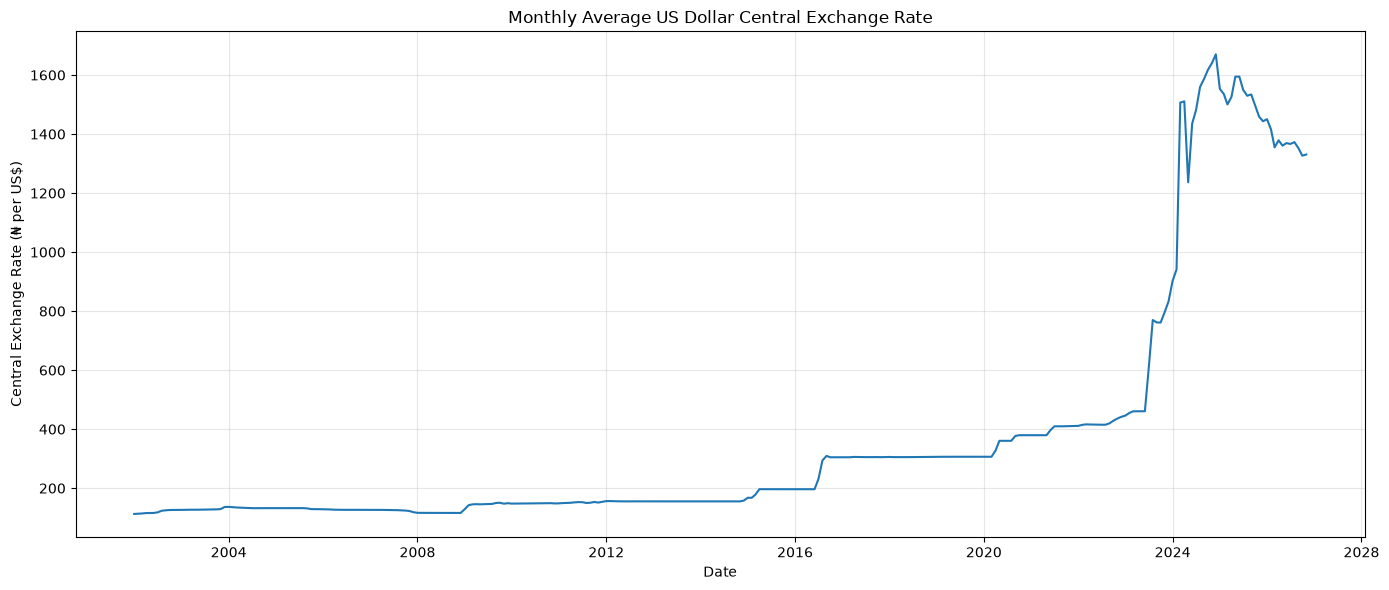

First month: 2001-12-31 00:00:00
Last month: 2026-10-31 00:00:00
Number of monthly periods: 299
Missing monthly values: 0


In [14]:
# Calculate the monthly arithmetic mean of the observed central rates
usd_monthly = usd_daily.resample("ME").mean()

# Plot the monthly exchange-rate series
plt.figure(figsize=(14, 6))
plt.plot(usd_monthly.index, usd_monthly.values)

plt.title("Monthly Average US Dollar Central Exchange Rate")
plt.xlabel("Date")
plt.ylabel("Central Exchange Rate (₦ per US$)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Inspect the resulting monthly series
print("First month:", usd_monthly.index.min())
print("Last month:", usd_monthly.index.max())
print("Number of monthly periods:", len(usd_monthly))
print("Missing monthly values:", usd_monthly.isna().sum())

## 2.2 Interpretation of the Monthly Exchange-Rate Series

The monthly US dollar central exchange-rate series contains 299 observations, covering December 2001 to October 2026. There are no missing monthly values, meaning that each month in this period has at least one recorded exchange-rate observation from which a monthly average can be calculated.

The line plot shows a general upward trend in the naira-per-dollar exchange rate over the period. The rate increases in stages, with particularly sharp movements around 2023–2024. Following a peak, the rate declines, indicating that the exchange rate does not increase continuously.

An increase in the naira-per-dollar rate means that more naira are required to purchase one US dollar, indicating a depreciation of the naira against the dollar. Conversely, a decline indicates that fewer naira are required per dollar.

Although the plot reveals a clear long-term movement and substantial fluctuations, it does not establish whether the series has a recurring seasonal pattern. Further analysis is required to separate the trend, seasonal component, and residual variation through time-series decomposition.

These observations will guide the next stages of the analysis, including smoothing, forecasting, and evaluating the predictive performance of the selected model.

## 3. Time-Series Decomposition

3.1 Decomposing the Monthly Exchange-Rate Series

Time-series decomposition is a technique used to separate an observed time series into different components to better understand its behaviour.

In this analysis, we will decompose the monthly US dollar central exchange-rate series into three components:

* Trend: The long-term direction of the exchange rate over time.
* Seasonality: A pattern that repeats at a regular interval, such as every 12 months.
* Residual: The remaining variation that is not explained by the estimated trend and seasonal components.

We will use seasonal decomposition from the statsmodels library. Since our observations are monthly, we will initially use a seasonal period of 12 to investigate whether the exchange rate exhibits an annual pattern.

The decomposition will help us examine the long-term movement of the exchange rate and determine whether a recurring seasonal pattern is visible. A 12-month period is a modelling assumption to investigate, not proof that annual seasonality exists in the data.

We start with additive decomposition to examine trend, seasonal and residuals. Additive is used when seasonal fluctuations are constant in absolute size, multiplicative when they change proportionally with the level. Because the exchange rate increased substantially, we will also test a log transformation to see if proportional changes fit better. The initial additive result will be kept for comparison, and the final model will be chosen based on the data.

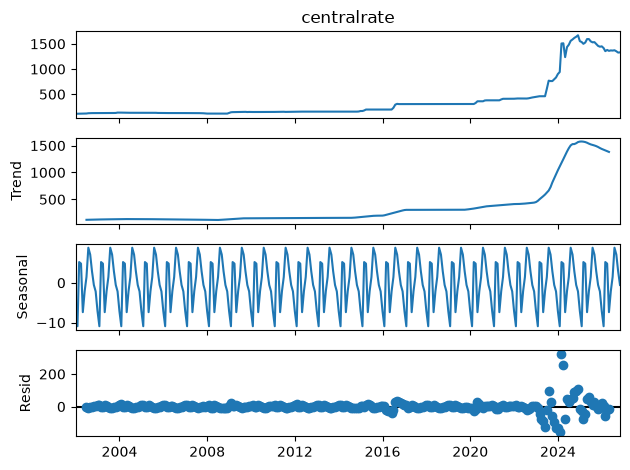

In [15]:
from statsmodels.tsa.seasonal import seasonal_decompose

# Decompose the monthly series using an additive model
decomposition = seasonal_decompose(
    usd_monthly,
    model="additive",
    period=12
)

# Plot the observed series and its estimated components
decomposition.plot()
plt.show()

## 3.2 Decomposition of the Log-Transformed Exchange-Rate Series

The original exchange-rate series shows a substantial change in level over time, particularly around 2023–2024. When the variability of a time series increases with its level, a logarithmic transformation can help represent proportional changes more consistently.

The natural logarithm of the monthly exchange rate will therefore be calculated, and the transformed series will be decomposed using an additive model with a seasonal period of 12 months. An additive decomposition of logged data can represent multiplicative relationships in the original series because logarithms convert multiplication into addition.

We will examine the trend, seasonal component, and residuals to assess whether the transformation provides a useful representation of the series. The transformation will not be assumed to eliminate all variability or establish that annual seasonality is present.

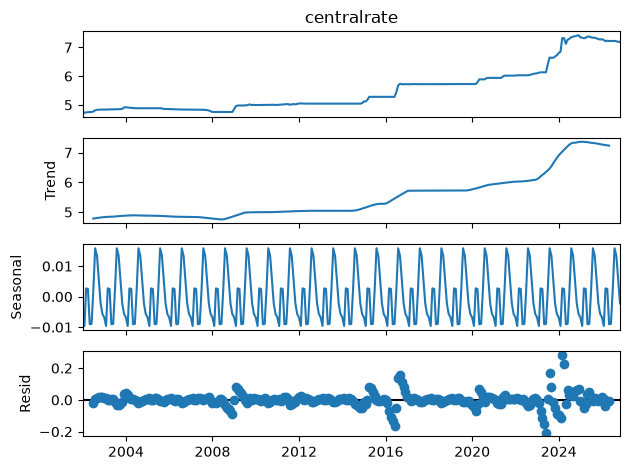

In [16]:
# Apply the natural logarithm to the positive monthly exchange rates
usd_log = np.log(usd_monthly)

# Decompose the log-transformed series using an additive model
log_decomposition = seasonal_decompose(
    usd_log,
    model="additive",
    period=12
)

# Plot the observed log series and its estimated components
log_decomposition.plot()
plt.show()

## 3.3 Interpretation of the Log-Transformed Decomposition

The log-transformed decomposition retains the overall upward trend observed in the original exchange-rate series, including the sharp increase around 2023–2024 and the subsequent decline. Applying the natural logarithm changes the scale of the data, making proportional changes easier to examine, but it does not eliminate the trend.

The estimated seasonal component fluctuates around zero with relatively small values. This suggests that the annual seasonal pattern is modest compared with the substantial long-term changes in the exchange rate. However, the decomposition alone does not establish that the observed seasonal pattern is statistically meaningful.

The residual component contains noticeable spikes, particularly around periods of major exchange-rate changes. This indicates that the trend and seasonal components do not fully explain these movements.

Overall, the log transformation provides a complementary view of the exchange-rate series, but it does not eliminate all changes in residual variability. Both decompositions will inform our subsequent smoothing and forecasting analysis.

## 4. Moving Average and Exponential Smoothing

4.1 Applying a Moving Average

A moving average is a smoothing technique that reduces short-term fluctuations in a time series by calculating the average of observations within a specified window.

In this analysis, we will calculate a three-month moving average of the monthly US dollar central exchange rate. For each month, the moving average will use the current month’s rate and the two preceding months.

The purpose is to smooth short-term movements and make the underlying direction of the exchange rate easier to observe. The moving average will be plotted alongside the original monthly series so that their patterns can be compared.

The three-month window is selected as a simple starting point for smoothing monthly data. It is a descriptive technique, not a forecasting model, and it may respond more slowly than the original series when the exchange rate changes sharply.

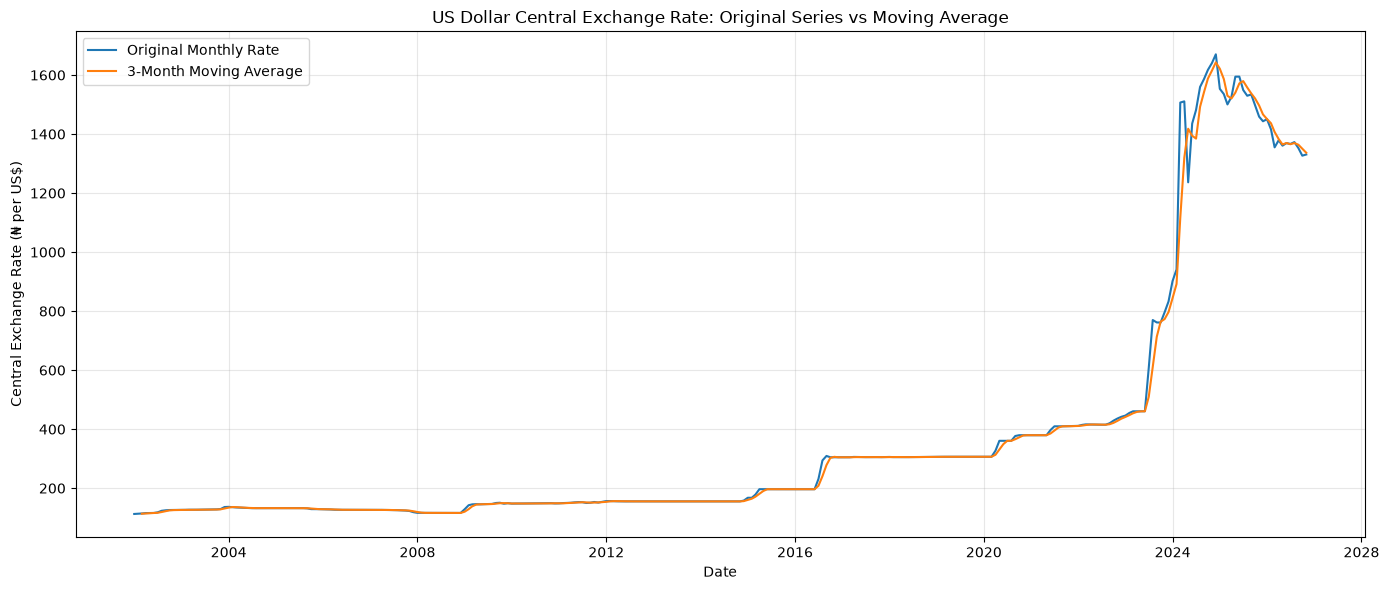

In [17]:
# Calculate a three-month moving average of the monthly exchange rate
usd_moving_average = usd_monthly.rolling(window=3).mean()

# Plot the original series and its moving average for comparison
plt.figure(figsize=(14, 6))
plt.plot(usd_monthly.index, usd_monthly, label="Original Monthly Rate")
plt.plot(usd_moving_average.index, usd_moving_average, label="3-Month Moving Average")

plt.title("US Dollar Central Exchange Rate: Original Series vs Moving Average")
plt.xlabel("Date")
plt.ylabel("Central Exchange Rate (₦ per US$)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 4.2 Interpretation of the Moving Average

The three-month moving average smooths some of the short-term fluctuations in the monthly US dollar central exchange-rate series, making the broader trend easier to observe.

The original series and the moving average both show a general upward movement, with particularly sharp changes around 2023–2024, followed by a decline from the peak. The moving average follows these movements but responds more gradually to sudden changes because each value is calculated from three consecutive monthly observations.

This illustrates the main benefit and limitation of moving averages: they help reveal the underlying direction of a time series, but smoothing can introduce a delay in responding to abrupt changes. The moving average is therefore useful for describing the series, although it is not, by itself, a complete forecasting model.

## 4.3 Applying Simple Exponential Smoothing

Exponential smoothing is a time-series technique that produces smoothed values by assigning greater weight to recent observations and progressively less weight to older observations.

In this analysis, we will apply simple exponential smoothing to the monthly US dollar central exchange-rate series. This method is suitable as a starting point because it models the series’ level without explicitly modelling a trend or seasonal component.

We will use a smoothing parameter, alpha, of 0.3. This value determines how strongly the smoothed series responds to recent observations. A lower alpha gives more weight to the previous smoothed value, producing a smoother series, while a higher alpha gives more weight to the latest observation.

We will plot the exponentially smoothed series alongside the original monthly exchange rate to examine how the method responds to changes in the data. This is a smoothing exercise; the resulting fitted series should not be interpreted as a validated forecast.

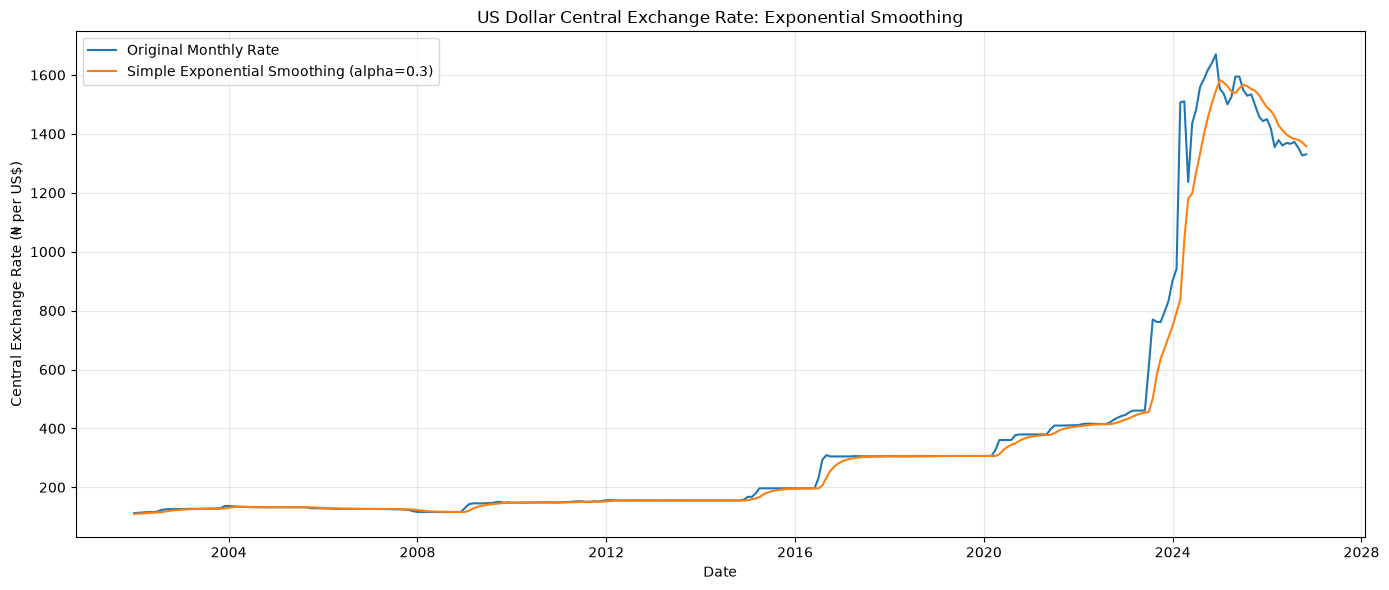

In [18]:
from statsmodels.tsa.holtwinters import SimpleExpSmoothing

# Fit simple exponential smoothing to the monthly exchange-rate series
ses_model = SimpleExpSmoothing(
    usd_monthly,
    initialization_method="estimated"
).fit(smoothing_level=0.3, optimized=False)

# Obtain the fitted, smoothed values
usd_exp_smoothing = ses_model.fittedvalues

# Plot the original series and exponentially smoothed values
plt.figure(figsize=(14, 6))
plt.plot(usd_monthly.index, usd_monthly, label="Original Monthly Rate")
plt.plot(
    usd_exp_smoothing.index,
    usd_exp_smoothing,
    label="Simple Exponential Smoothing (alpha=0.3)"
)

plt.title("US Dollar Central Exchange Rate: Exponential Smoothing")
plt.xlabel("Date")
plt.ylabel("Central Exchange Rate (₦ per US$)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

4.4 Interpretation of Simple Exponential Smoothing

Simple exponential smoothing creates a smoother series by weighting recent observations more heavily than older ones.

The smoothed line follows the general trend but lags behind sharp moves, notably the 2023-2024 devaluation. This lag is inherent because each smoothed value is a weighted average of the current observation and past smoothed values.

With alpha = 0.3, 30% weight is given to the current month and 70% to history. This produces moderate smoothing - it reduces monthly noise while retaining the underlying trend.

The plot shows fitted values only, not forecasts. Forecast accuracy must be evaluated separately on out-of-sample data.

## 5. Time Series Forecasting

 Training and Testing Split

The monthly USD series (n=299 months, Dec 2001 - Oct 2026) is split chronologically: first 80% for training (∼239 months), last 20% for testing (∼60 months).

A naive baseline is used for comparison. It forecasts each test month as the last observed training value. This is a flat forecast and provides a minimum benchmark.

All models (Naive, ARIMA/SARIMA) are evaluated on the same test period, so improvement is measured against the baseline, not assumed from complexity.

In [19]:
# Calculate the position separating the training and testing periods
split_point = int(len(usd_monthly) * 0.8)

# Use earlier observations for training and later observations for testing
train = usd_monthly.iloc[:split_point]
test = usd_monthly.iloc[split_point:]

# Inspect the split to confirm that the time order is preserved
print("Training observations:", len(train))
print("Testing observations:", len(test))
print("Training period:", train.index.min(), "to", train.index.max())
print("Testing period:", test.index.min(), "to", test.index.max())

Training observations: 239
Testing observations: 60
Training period: 2001-12-31 00:00:00 to 2021-10-31 00:00:00
Testing period: 2021-11-30 00:00:00 to 2026-10-31 00:00:00


## 5.1 Building a Naive Baseline Forecast

A naive forecast predicts that the exchange rate will remain at its last observed training value throughout the test period.

We will use this as a baseline to determine whether ARIMA or SARIMA can forecast the exchange rate more accurately. All models will be evaluated on the same test period.

In [20]:
# Use the last training observation as the forecast for every test month
naive_forecast = np.repeat(train.iloc[-1], len(test))

# Display the baseline forecast
print("Last training exchange rate:", round(train.iloc[-1], 2))
print("Number of forecast months:", len(naive_forecast))
print("First five baseline predictions:", naive_forecast[:5])

Last training exchange rate: 410.41
Number of forecast months: 60
First five baseline predictions: [410.41263158 410.41263158 410.41263158 410.41263158 410.41263158]


## 5.2 Evaluating the Naive Baseline Forecast

We will compare the naive baseline predictions with the actual exchange rates in the test period using RMSE and MAE.

* RMSE (Root Mean Squared Error): Penalizes larger forecast errors more heavily.
* MAE (Mean Absolute Error): Measures the average absolute difference between predicted and actual exchange rates.

These metrics establish a baseline for comparison with the ARIMA or SARIMA model. Lower values indicate more accurate forecasts.

In [21]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Compare baseline predictions with the actual test observations
baseline_rmse = np.sqrt(mean_squared_error(test, naive_forecast))
baseline_mae = mean_absolute_error(test, naive_forecast)

print("Naive Baseline RMSE:", round(baseline_rmse, 2))
print("Naive Baseline MAE:", round(baseline_mae, 2))

Naive Baseline RMSE: 805.9
Naive Baseline MAE: 643.17


## 5.3 Building a Seasonal-Naive Baseline Forecast

The seasonal-naive method predicts each month using the observed value from the same month one year earlier. We will repeat the final 12 months of the training data to cover the 60-month test period.

In [22]:
# Repeat the final 12 months of training data across the test period
seasonal_naive_forecast = np.tile(
    train.iloc[-12:].to_numpy(),
    int(np.ceil(len(test) / 12))
)[:len(test)]

# Keep predictions aligned with the test dates
seasonal_naive_forecast = pd.Series(
    seasonal_naive_forecast,
    index=test.index
)

print("Number of seasonal-naive predictions:", len(seasonal_naive_forecast))
print("\nFirst five predictions:")
display(seasonal_naive_forecast.head())

Number of seasonal-naive predictions: 60

First five predictions:


ratedate
2021-11-30    379.5
2021-12-31    379.5
2022-01-31    379.5
2022-02-28    379.5
2022-03-31    379.5
Freq: ME, dtype: float64

## 5.4 Evaluating the Seasonal-Naive Baseline

We will evaluate the seasonal-naive predictions using RMSE and MAE, then compare them with the ordinary naive baseline. Lower error values indicate better forecasts on the same test period.

In [23]:
# Calculate seasonal-naive forecast errors
seasonal_naive_rmse = np.sqrt(
    mean_squared_error(test, seasonal_naive_forecast)
)
seasonal_naive_mae = mean_absolute_error(
    test, seasonal_naive_forecast
)

# Compare both baseline methods
baseline_comparison = pd.DataFrame({
    "Model": ["Ordinary Naive", "Seasonal Naive"],
    "RMSE": [baseline_rmse, seasonal_naive_rmse],
    "MAE": [baseline_mae, seasonal_naive_mae]
})

display(baseline_comparison.round(2))

,Model,RMSE,MAE
0,Ordinary Naive,805.90,643.17
1,Seasonal Naive,818.45,659.96


Interpretation

The ordinary-naive baseline achieved an RMSE of 805.90 and an MAE of 643.17, while the seasonal-naive baseline recorded an RMSE of 818.45 and an MAE of 659.96.

The ordinary-naive method performed slightly better on both metrics. Therefore, repeating the previous month’s rate provided a better baseline than repeating the rate from the same month in the previous year. We will use these results to assess whether ARIMA/SARIMA improves forecasting accuracy.

## 5.5 Checking Stationarity

Before fitting ARIMA/SARIMA, we will test whether the training series is stationary using the Augmented Dickey-Fuller (ADF) test. This helps us determine whether differencing may be needed to remove non-stationarity.

In [24]:
from statsmodels.tsa.stattools import adfuller

# Test the original training series, without applying a log transformation
adf_result = adfuller(train.dropna())

print("ADF statistic:", round(adf_result[0], 4))
print("p-value:", round(adf_result[1], 4))
print("5% critical value:", round(adf_result[4]["5%"], 4))

if adf_result[1] < 0.05:
    print("Conclusion: Reject the null hypothesis; evidence suggests the series is stationary.")
else:
    print("Conclusion: Fail to reject the null hypothesis; the series may be non-stationary.")

ADF statistic: 0.9983
p-value: 0.9942
5% critical value: -2.8739
Conclusion: Fail to reject the null hypothesis; the series may be non-stationary.


C:\Users\user\AppData\Local\Temp\ipykernel_26068\2905048496.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(train.dropna())


## 5.6 Comparing Differencing Methods for Stationarity

The original training series was non-stationary according to the ADF test. We will compare four versions of the series: the original data, first differencing, seasonal differencing at lag 12, and both differences combined. We will use the ADF test to assess each version and guide our choice of differencing for ARIMA/SARIMA.

In [25]:
from statsmodels.tsa.stattools import adfuller
import pandas as pd

# Prepare the four versions of the training series
series_versions = {
    "Original": train,
    "First difference (d=1)": train.diff(),
    "Seasonal difference (D=1, lag=12)": train.diff(12),
    "First + seasonal difference (d=1, D=1)": train.diff().diff(12)
}

# Test each version and collect the results
results = []

for name, series in series_versions.items():
    series = series.dropna()
    adf_result = adfuller(series)

    results.append({
        "Series": name,
        "ADF statistic": round(adf_result[0], 4),
        "p-value": round(adf_result[1], 4),
        "5% critical value": round(adf_result[4]["5%"], 4),
        "Stationary at 5%": adf_result[1] < 0.05
    })

adf_comparison = pd.DataFrame(results)
display(adf_comparison)

C:\Users\user\AppData\Local\Temp\ipykernel_26068\312201387.py:17: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(series)
C:\Users\user\AppData\Local\Temp\ipykernel_26068\312201387.py:17: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(series)
C:\Users\user\AppData\Local\Temp\ipykernel_26068\312201387.py:17: FutureWarning: adfuller 

,Series,ADF statistic,p-value,5% critical value,Stationary at 5%
0,Original,0.9983,0.9942,-2.8739,False
1,First difference (d=1),-7.3102,0.0000,-2.8739,True
2,"Seasonal difference (D=1, lag=12)",-2.3769,0.1484,-2.8753,False
3,"First + seasonal difference (d=1, D=1)",-4.4450,0.0002,-2.8753,True


Interpretation

The ADF test results indicate that the original training series is non-stationary. After first differencing, the p-value falls below the 5% significance level, providing evidence that the differenced series is stationary. Seasonal differencing alone does not produce the same result, while applying both differences also produces a stationary result according to the ADF test.

Since first differencing alone appears sufficient, we will initially use an ordinary differencing order of (d=1) and a seasonal differencing order of (D=0). We will examine the ACF and PACF plots of the first-differenced series to guide the selection of AR and MA terms, including any evidence of seasonal dependence.

## 5.7 Autocorrelation and Partial Autocorrelation Analysis

The ADF test suggests that first differencing makes the training series stationary. We will now plot the Autocorrelation Function (ACF) and Partial Autocorrelation Function (PACF) of the first-differenced training series.

The ACF helps us identify potential Moving Average (MA) terms, while the PACF helps us identify potential Autoregressive (AR) terms. We will examine the significant spikes, including those at seasonal lags such as 12, to guide our initial model choices.

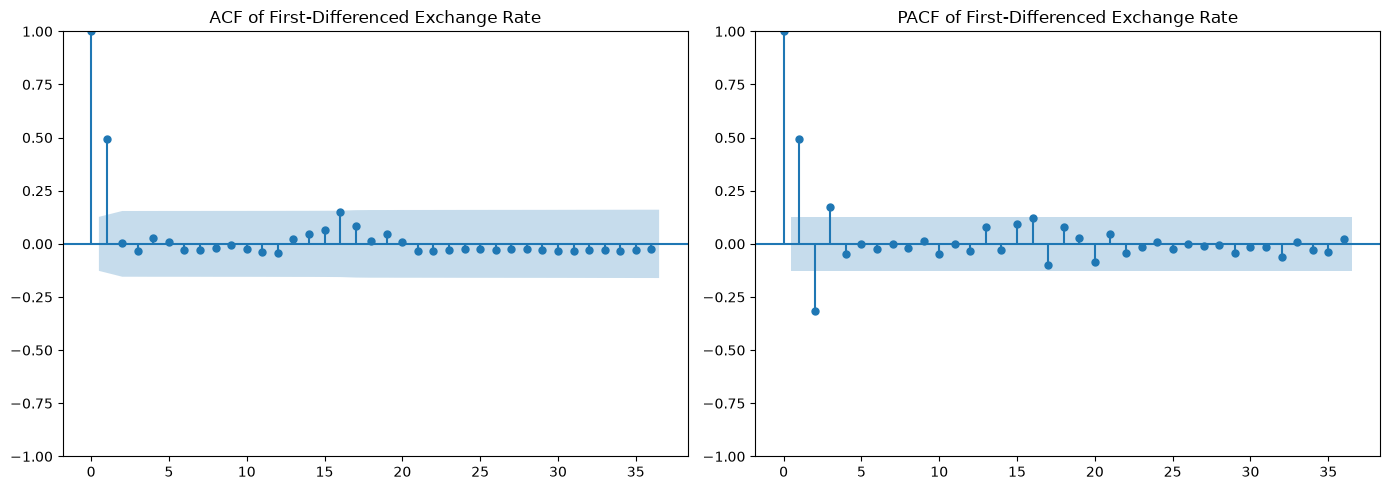

In [26]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# First-difference the training series
train_diff = train.diff().dropna()

# Plot ACF and PACF side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_acf(train_diff, lags=36, ax=axes[0])
axes[0].set_title("ACF of First-Differenced Exchange Rate")

plot_pacf(train_diff, lags=36, ax=axes[1], method="ywm")
axes[1].set_title("PACF of First-Differenced Exchange Rate")

plt.tight_layout()
plt.show()

## 5.8 Fitting and Comparing ARIMA Models

The ACF and PACF plots provide guidance for selecting ARIMA model parameters, but they do not identify the best model with certainty. We will fit a small number of candidate ARIMA models using the training data and compare their forecasting performance.

Based on the ADF test, we will begin with first differencing ((d=1)). We will test different combinations of autoregressive ((p)) and moving-average ((q)) terms. Each model will be evaluated on the same test period using RMSE and MAE, allowing us to compare its performance with the naive baseline forecasts established earlier.

In [27]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np
import pandas as pd

# Candidate models: keep the differencing order at d=1
candidate_orders = [
    (1, 1, 0),
    (2, 1, 0),
    (0, 1, 1),
    (1, 1, 1),
    (2, 1, 1)
]

arima_results = []

for order in candidate_orders:
    try:
        # Fit each model using training data only
        model = ARIMA(train, order=order).fit()

        # Forecast exactly as many periods as appear in the test set
        forecast = model.forecast(steps=len(test))
        forecast.index = test.index

        # Evaluate predictions against the actual test values
        rmse = np.sqrt(mean_squared_error(test, forecast))
        mae = mean_absolute_error(test, forecast)

        arima_results.append({
            "ARIMA Order": str(order),
            "RMSE": rmse,
            "MAE": mae,
            "AIC": model.aic
        })

    except Exception as error:
        print(f"ARIMA{order} could not be fitted: {error}")

arima_comparison = (
    pd.DataFrame(arima_results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

display(arima_comparison.round(2))

,ARIMA Order,RMSE,MAE,AIC
0,"(1, 1, 0)",805.57,642.77,1465.83
1,"(1, 1, 1)",805.59,642.78,1438.53
2,"(2, 1, 1)",805.62,642.82,1439.93
3,"(0, 1, 1)",805.69,642.91,1438.93
4,"(2, 1, 0)",805.85,643.11,1446.20


In [28]:
# Refit the selected unlogged ARIMA(1, 1, 1) model(This is done so we can call the variable name when we are comparing all models)
# using the training data only.

arima_111_model = ARIMA(train, order=(1, 1, 1)).fit()

# Forecast the full test period.
arima_111_forecast = arima_111_model.forecast(steps=len(test))
arima_111_forecast.index = test.index

# Evaluate the forecast against the actual test values.
arima_111_rmse = np.sqrt(mean_squared_error(test, arima_111_forecast))
arima_111_mae = mean_absolute_error(test, arima_111_forecast)
arima_111_aic = arima_111_model.aic

# Save and display the evaluation results.
arima_111_results = pd.DataFrame([{
    "Model": "Unlogged ARIMA(1, 1, 1)",
    "RMSE": arima_111_rmse,
    "MAE": arima_111_mae,
    "AIC": arima_111_aic
}])

display(arima_111_results.round(2))

,Model,RMSE,MAE,AIC
0,"Unlogged ARIMA(1, 1, 1)",805.59,642.78,1438.53


## 5.9 Visualizing the Selected ARIMA(1, 1, 1) Forecast

After comparing five candidate ARIMA models, we selected ARIMA(1, 1, 1) for further analysis because it had the lowest Akaike Information Criterion (AIC) of 1438.53. AIC helps compare model fit while accounting for model complexity.

However, ARIMA(1, 1, 0) achieved slightly lower RMSE and MAE on the test set. The forecasting errors of the candidate models were very similar, so ARIMA(1, 1, 1) is a reasonable model to examine further, rather than a model proven to be the best under every evaluation criterion.

The parameters mean:

* p = 1: one autoregressive term.
* d = 1: one level of differencing.
* q = 1: one moving-average term.

We will plot the selected model’s forecasts against the actual test-period exchange rates to visually assess its forecasting performance. The model will be fitted using training data only, and the forecast will cover the same test period used for the baseline and candidate-model evaluations.

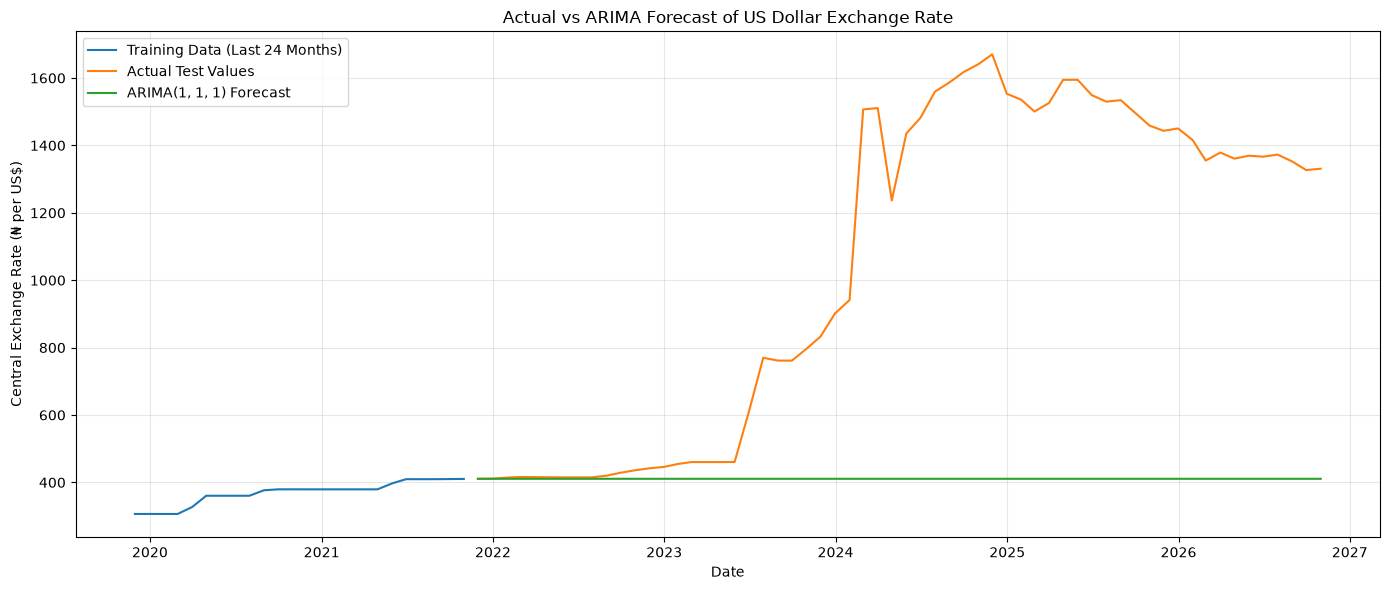

In [29]:
# Fit the selected ARIMA model using the training data
final_arima_model = ARIMA(train, order=(1, 1, 1)).fit()

# Forecast the test period
arima_forecast = final_arima_model.forecast(steps=len(test))

# Align forecast dates with the actual test dates
arima_forecast.index = test.index

# Plot actual values against the ARIMA forecast
plt.figure(figsize=(14, 6))
plt.plot(train.index[-24:], train.iloc[-24:], label="Training Data (Last 24 Months)")
plt.plot(test.index, test, label="Actual Test Values")
plt.plot(arima_forecast.index, arima_forecast, label="ARIMA(1, 1, 1) Forecast")

plt.title("Actual vs ARIMA Forecast of US Dollar Exchange Rate")
plt.xlabel("Date")
plt.ylabel("Central Exchange Rate (₦ per US$)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Interpretation of the ARIMA(1,1,1) Forecast

The forecast plot shows that the ARIMA(1,1,1) model failed to capture the sharp increases in the exchange rate from 2023 onward. While the actual exchange rate rose substantially, the model’s forecast continued to decline.

This indicates poor forecasting performance on the test data. Therefore, we will investigate the ACF and PACF plots of the log-transformed training series to guide the selection of alternative model orders.

## 6. Evaluating a Log Transformation

The exchange-rate series contains substantial changes in its level over time. We will investigate whether applying the natural logarithm makes the series easier to model.

The log transformation compresses larger values more than smaller ones and can help stabilize variation when fluctuations increase with the series level. However, it does not automatically make a series stationary.

We will transform the existing training and test series separately, inspect the transformed training data, and then evaluate stationarity using the training data only. The existing chronological split will remain unchanged.

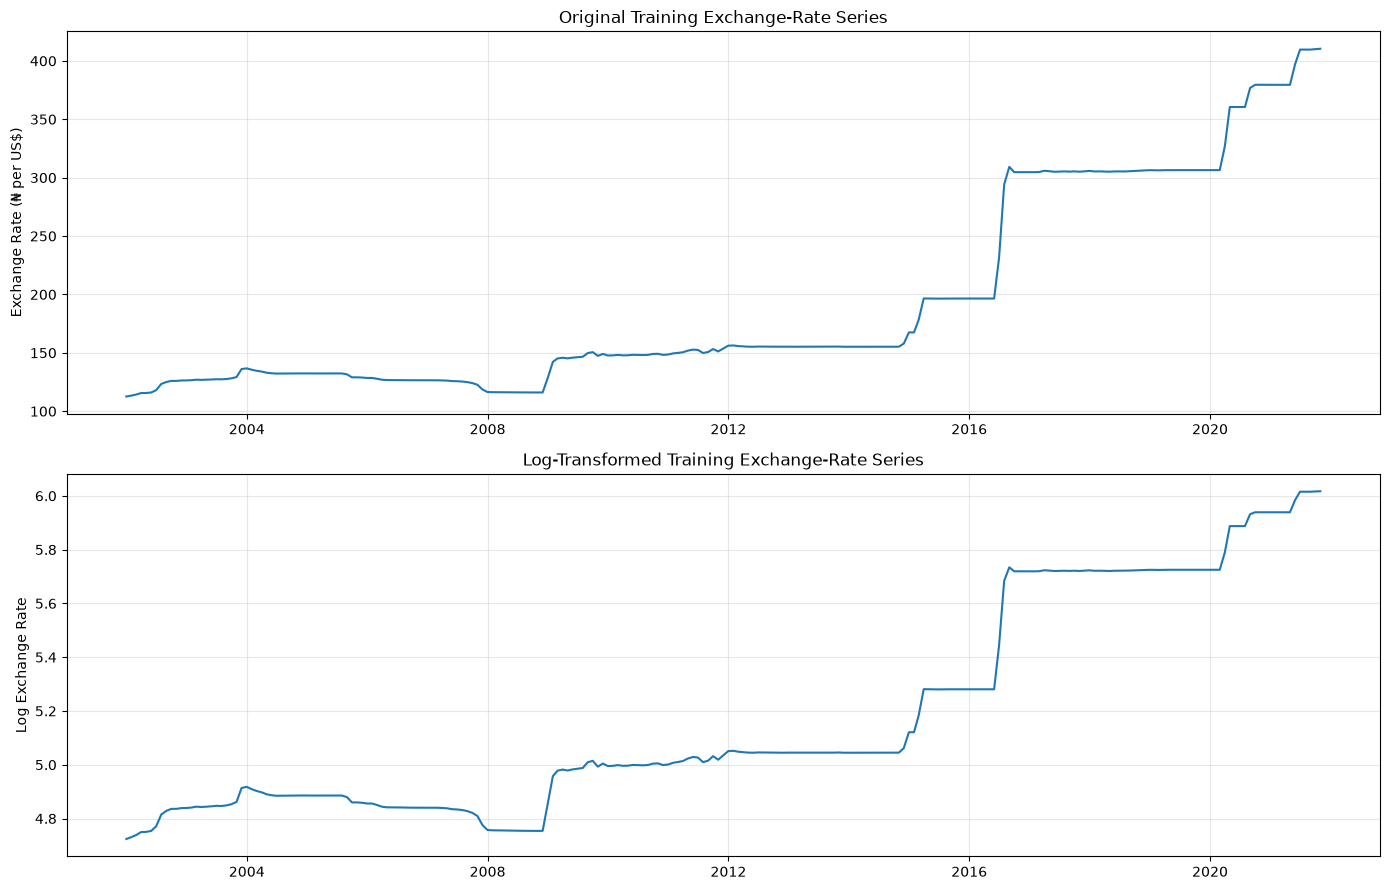

Log training observations: 239
Log test observations: 60
Missing values in log training data: 0
Missing values in log test data: 0
Infinite values in log training data: 0
Infinite values in log test data: 0


In [30]:
# Apply the natural logarithm to the existing train and test series
log_train = np.log(train)
log_test = np.log(test)

# Compare the original and log-transformed training series
fig, axes = plt.subplots(2, 1, figsize=(14, 9))

axes[0].plot(train.index, train)
axes[0].set_title("Original Training Exchange-Rate Series")
axes[0].set_ylabel("Exchange Rate (₦ per US$)")
axes[0].grid(True, alpha=0.3)

axes[1].plot(log_train.index, log_train)
axes[1].set_title("Log-Transformed Training Exchange-Rate Series")
axes[1].set_ylabel("Log Exchange Rate")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Confirm that the transformation produced valid values
print("Log training observations:", len(log_train))
print("Log test observations:", len(log_test))
print("Missing values in log training data:", log_train.isna().sum())
print("Missing values in log test data:", log_test.isna().sum())
print("Infinite values in log training data:", np.isinf(log_train).sum())
print("Infinite values in log test data:", np.isinf(log_test).sum())

## 6.1 Examining ACF and PACF After Log Transformation

The previous ARIMA(1,1,1) model did not adequately capture the observed exchange-rate movements. We will examine the ACF and PACF plots of the log-transformed training series to guide the selection of alternative ARIMA orders.

* ACF: Helps identify potential moving-average (MA) terms.
* PACF: Helps identify potential autoregressive (AR) terms.

We will examine the significant spikes and their lag positions to select candidate model orders for further testing. The plots will guide our choices but will not determine the best model on their own.

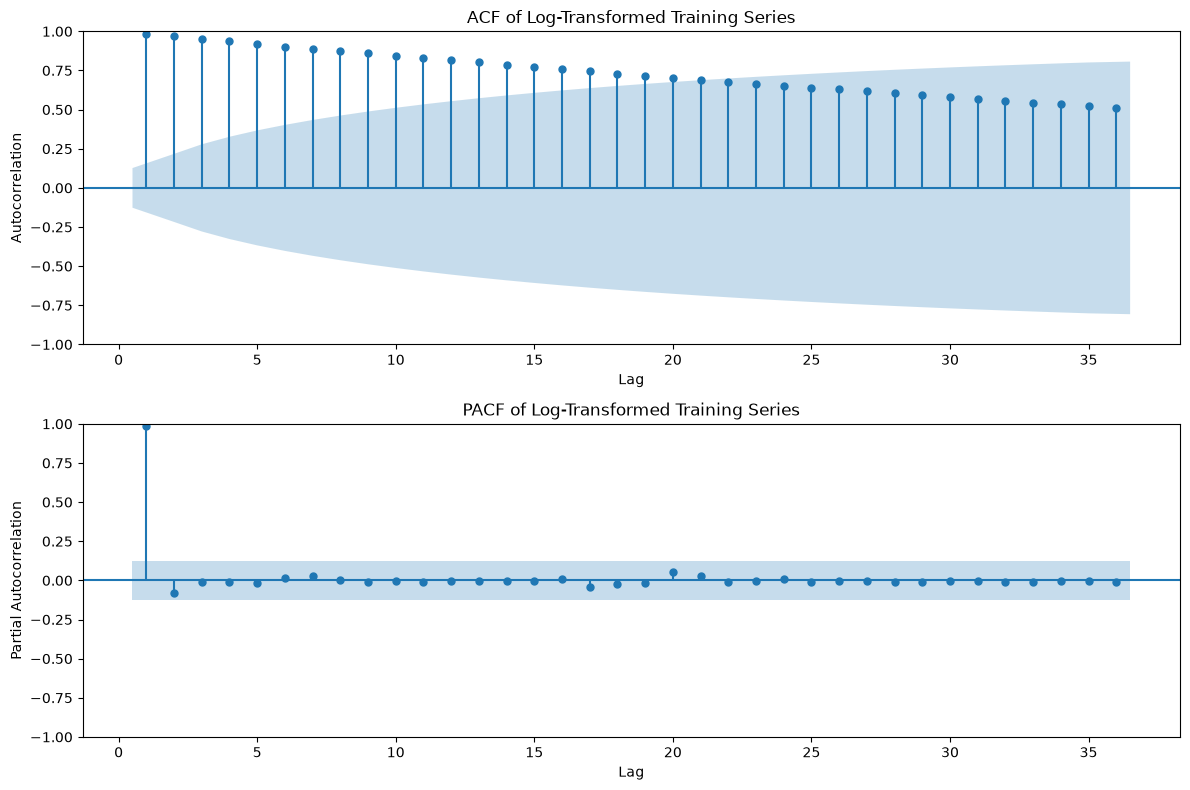

In [31]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

# Plot ACF and PACF for the log-transformed training series
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

plot_acf(log_train, lags=36, ax=axes[0], zero=False)
axes[0].set_title("ACF of Log-Transformed Training Series")
axes[0].set_xlabel("Lag")
axes[0].set_ylabel("Autocorrelation")

plot_pacf(log_train, lags=36, ax=axes[1], method="ywm", zero=False)
axes[1].set_title("PACF of Log-Transformed Training Series")
axes[1].set_xlabel("Lag")
axes[1].set_ylabel("Partial Autocorrelation")

plt.tight_layout()
plt.show()

Interpretation of ACF and PACF Results

The ACF decreases slowly and remains strongly positive across many lags, indicating strong persistence in the log-transformed exchange-rate series. The PACF shows a strong spike at the first lag, while most subsequent lags have relatively small partial autocorrelations.

These patterns suggest that the log transformation alone has not removed the series’ persistent trend. We should test for stationarity before selecting another ARIMA model.

## 6.2 Testing Stationarity After Log Transformation

The ACF and PACF plots suggest that the log-transformed series still exhibits strong persistence. We will use the Augmented Dickey–Fuller (ADF) test to check whether the log transformation has made the training series stationary.

The null hypothesis states that the series has a unit root and is non-stationary. A p-value below 0.05 provides evidence to reject this hypothesis.

In [32]:
from statsmodels.tsa.stattools import adfuller

# Test the log-transformed training series
adf_result = adfuller(log_train.dropna())

print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])
print("Critical Values:")
for level, value in adf_result[4].items():
    print(f"  {level}: {value}")

ADF Statistic: 0.5356936611080027
p-value: 0.9859185358903292
Critical Values:
  1%: -3.4586084859607156
  5%: -2.873972159235721
  10%: -2.57339565928848


C:\Users\user\AppData\Local\Temp\ipykernel_26068\4175763839.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(log_train.dropna())


Interpretation of the ADF Test on the Log-Transformed Training Series

The Augmented Dickey-Fuller (ADF) test produced a test statistic of 0.536 and a p-value of 0.986.

Since the p-value is greater than 0.05, we fail to reject the null hypothesis that the series has a unit root. The test statistic is also greater than the critical values at the 1%, 5%, and 10% significance levels.

Therefore, the log transformation alone did not make the training series stationary. Further differencing may be required before fitting the ARIMA model.

## 6.3 Testing Stationarity After First-Order Differencing

Since the ADF test showed that the log-transformed training series is non-stationary, we will apply first-order differencing to remove changes in its level over time.

We will then run the ADF test again to determine whether the differenced series is stationary. This will help us decide whether further differencing is needed when specifying the ARIMA model.

In [33]:
# Apply first-order differencing to the log-transformed training series
log_train_diff = log_train.diff().dropna()

# Test the differenced series for stationarity
adf_diff_result = adfuller(log_train_diff)

print("ADF Statistic:", adf_diff_result[0])
print("p-value:", adf_diff_result[1])
print("Critical Values:")

for level, value in adf_diff_result[4].items():
    print(f"  {level}: {value}")

ADF Statistic: -7.210749980727241
p-value: 2.2382121999482647e-10
Critical Values:
  1%: -3.4586084859607156
  5%: -2.873972159235721
  10%: -2.57339565928848


C:\Users\user\AppData\Local\Temp\ipykernel_26068\2661103374.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_diff_result = adfuller(log_train_diff)


Interpretation of the ADF Test After First-Order Differencing

The ADF test produced a test statistic of -7.2107 and a p-value close to zero ((2.24 \times 10^{-10})).

Since the p-value is below 0.05 and the test statistic is below the 5% critical value, we reject the null hypothesis of a unit root.

Therefore, the first-differenced log-transformed training series is stationary. This supports using (d = 1) in the ARIMA model.

## 6.4 Examining ACF and PACF After First-Order Differencing

The ADF test indicates that the first-differenced log-transformed training series is stationary. We will examine its Autocorrelation Function (ACF) and Partial Autocorrelation Function (PACF) plots to understand the remaining autocorrelation patterns and help guide the selection of the ARIMA parameters (p) and (q).

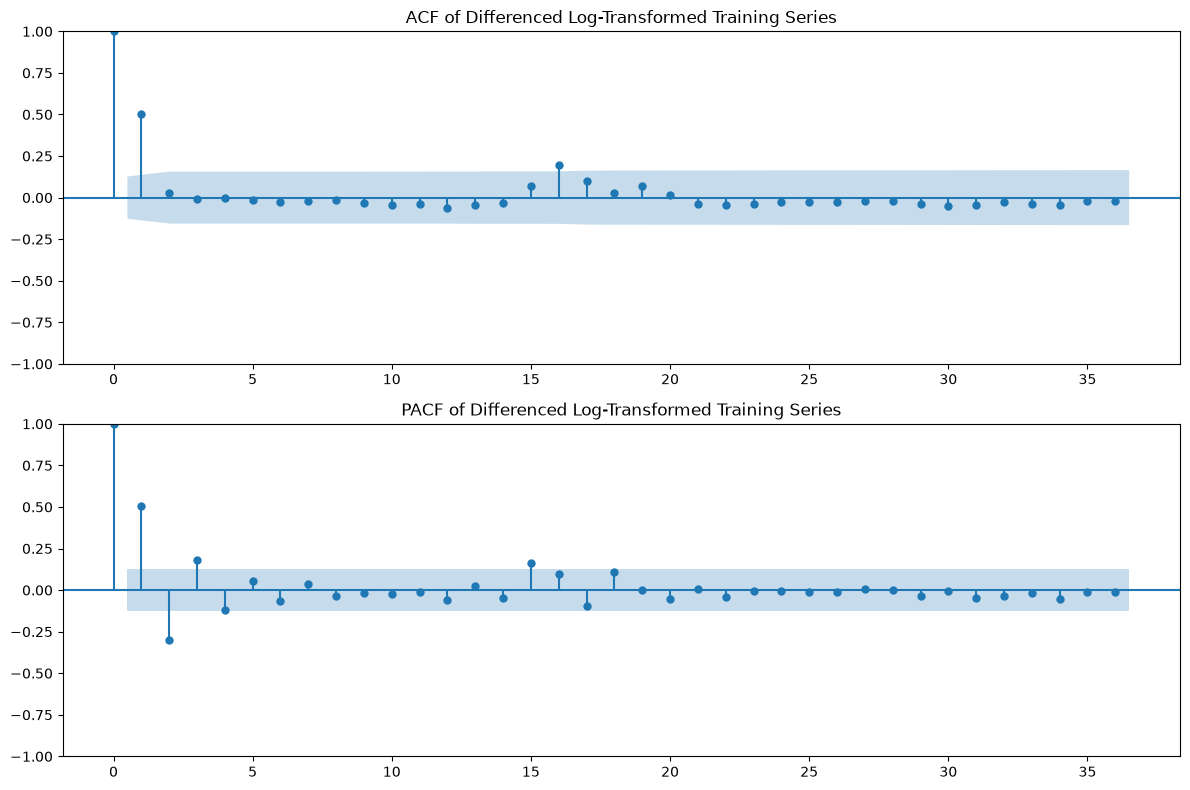

In [34]:
# Plot ACF and PACF for the stationary, differenced training series
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

plot_acf(log_train_diff, lags=36, ax=axes[0])
axes[0].set_title("ACF of Differenced Log-Transformed Training Series")

plot_pacf(log_train_diff, lags=36, ax=axes[1], method="ywm")
axes[1].set_title("PACF of Differenced Log-Transformed Training Series")

plt.tight_layout()
plt.show()

Interpretation of ACF/PACF After First-Differencing (log training series)

The first-differenced log series is stationary per ADF test, but still autocorrelated.

- ACF: Large positive spike at lag 1, then mostly small/insignificant autocorrelations, with a few later lags outside bounds.

- PACF: Strong positive at lag 1 and negative at lag 2, with additional significant negative spikes at higher lags.

This pattern indicates a low-order ARMA remains (AR(1) or AR(2) / MA(1) signature) plus some longer-term dependence.

ACF/PACF are used only for initial order guidance. Final order selection will be based on test-set RMSE, not visual inspection alone.

## 6.5 Selecting Candidate ARIMA Order

The ACF and PACF plots guide our choice of ARIMA orders. We will compare several combinations of (p) and (q), keeping (d=1) because the ADF test found the first-differenced log series to be stationary.

We will compare the models using AIC. A lower AIC indicates a better balance between model fit and complexity among the candidates. We will later evaluate forecasting performance using test data and RMSE.

In [35]:
# Compare a small range of ARIMA orders, keeping d = 1
candidate_orders = [
    (0, 1, 1),
    (0, 1, 2),
    (1, 1, 0),
    (1, 1, 1),
    (1, 1, 2),
    (2, 1, 0),
    (2, 1, 1),
    (2, 1, 2),
    (3, 1, 0),
    (3, 1, 1),
    (3, 1, 2)
]

arima_results = []

for order in candidate_orders:
    try:
        fitted_model = ARIMA(log_train, order=order).fit()
        arima_results.append({
            "ARIMA Order": str(order),
            "AIC": fitted_model.aic
        })
    except Exception as error:
        print(f"ARIMA{order} failed: {error}")

arima_comparison = (
    pd.DataFrame(arima_results)
    .sort_values("AIC")
    .reset_index(drop=True)
)

display(arima_comparison.round(3))

,ARIMA Order,AIC
0,"(0, 1, 1)",-1176.695
1,"(1, 1, 1)",-1176.151
2,"(0, 1, 2)",-1176.072
3,"(1, 1, 2)",-1174.307
4,"(2, 1, 1)",-1174.235
5,"(2, 1, 2)",-1172.460
6,"(3, 1, 1)",-1172.251
7,"(3, 1, 2)",-1170.358
8,"(3, 1, 0)",-1169.328
9,"(2, 1, 0)",-1161.274


Interpretation of ARIMA Order Selection

Among the 11 candidate ARIMA models tested, ARIMA(0, 1, 1) recorded the lowest AIC value of −1176.695. This makes it our preferred ARIMA candidate based on the current AIC comparison.

We will retain this model for forecasting and later evaluate its performance on the test data using RMSE. The model is not yet considered the final choice, as its forecasting accuracy must be compared with that of the SARIMA model.

## 6.6 Selecting a Candidate SARIMA Model

SARIMA extends ARIMA by incorporating seasonal terms. Since our data is monthly, we will test a seasonal period of 12 months to investigate whether annual patterns improve model fit.

We will compare a small set of SARIMA configurations using AIC. The best candidate will later be evaluated against ARIMA using the same test period and RMSE.

In [36]:
# Compare 10 candidate SARIMA models using a 12-month seasonal period
sarima_orders = [
    ((0, 1, 1), (0, 0, 1, 12)),
    ((0, 1, 1), (1, 0, 0, 12)),
    ((0, 1, 1), (1, 0, 1, 12)),
    ((1, 1, 1), (0, 0, 1, 12)),
    ((1, 1, 1), (1, 0, 0, 12)),
    ((1, 1, 1), (1, 0, 1, 12)),
    ((2, 1, 1), (0, 0, 1, 12)),
    ((2, 1, 1), (1, 0, 0, 12)),
    ((2, 1, 1), (1, 0, 1, 12)),
    ((0, 1, 2), (1, 0, 1, 12))
]

sarima_results = []

for order, seasonal_order in sarima_orders:
    try:
        fitted_model = ARIMA(
            log_train,
            order=order,
            seasonal_order=seasonal_order
        ).fit()

        sarima_results.append({
            "ARIMA Order": str(order),
            "Seasonal Order": str(seasonal_order),
            "AIC": fitted_model.aic
        })

    except Exception as error:
        print(f"Model {order} × {seasonal_order} failed: {error}")

sarima_comparison = (
    pd.DataFrame(sarima_results)
    .sort_values("AIC")
    .reset_index(drop=True)
)

display(sarima_comparison.round(3))

,ARIMA Order,Seasonal Order,AIC
0,"(0, 1, 1)","(1, 0, 0, 12)",-1175.194
1,"(0, 1, 1)","(0, 0, 1, 12)",-1175.186
2,"(1, 1, 1)","(1, 0, 0, 12)",-1174.652
3,"(1, 1, 1)","(0, 0, 1, 12)",-1174.639
4,"(0, 1, 1)","(1, 0, 1, 12)",-1173.184
5,"(2, 1, 1)","(1, 0, 0, 12)",-1172.701
6,"(2, 1, 1)","(0, 0, 1, 12)",-1172.689
7,"(1, 1, 1)","(1, 0, 1, 12)",-1172.638
8,"(0, 1, 2)","(1, 0, 1, 12)",-1172.569
9,"(2, 1, 1)","(1, 0, 1, 12)",-1170.689


Interpretation of SARIMA Model Comparison

The 10 SARIMA combinations were compared using the Akaike Information Criterion (AIC). The model with the lowest AIC was SARIMA(0,1,1)(1,0,0,12), with an AIC of -1175.194.

This model uses first-order non-seasonal differencing and a non-seasonal moving-average component, together with a seasonal autoregressive component at a 12-month period.

We will select this model as our leading SARIMA candidate for forecasting. Its performance will later be compared with the selected ARIMA model using the same test period and RMSE. The final choice will therefore depend on out-of-sample forecasting performance, not AIC alone.

## 6.7 Evaluating Candidate ARIMA and SARIMA Models

We will fit the candidate ARIMA and SARIMA models using the log-transformed training data and generate predictions for the test period. We will compare these predictions with the actual test values using RMSE and MAE to identify which model performs better.

In [37]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
# Fit the candidate ARIMA model
arima_model = ARIMA(log_train, order=(0, 1, 1)).fit()

# Fit the candidate SARIMA model
sarima_model = ARIMA(
    log_train,
    order=(0, 1, 1),
    seasonal_order=(1, 0, 0, 12)
).fit()

# Generate predictions for the test period
arima_log_pred = arima_model.forecast(steps=len(log_test))
sarima_log_pred = sarima_model.forecast(steps=len(log_test))

# Convert predictions back to the original exchange-rate scale
arima_pred = np.exp(arima_log_pred)
sarima_pred = np.exp(sarima_log_pred)

print("ARIMA predictions:", len(arima_pred))
print("SARIMA predictions:", len(sarima_pred))
print("Actual test observations:", len(test))

ARIMA predictions: 60
SARIMA predictions: 60
Actual test observations: 60


## 6.8 Comparing Model Performance
We will evaluate the ARIMA and SARIMA predictions against the actual test data using RMSE and MAE. These metrics will help us compare their predictive accuracy and identify the preferred model.

In [38]:
# Calculate RMSE and MAE for both models
from sklearn.metrics import mean_squared_error, mean_absolute_error

arima_rmse = np.sqrt(mean_squared_error(test, arima_pred))
arima_mae = mean_absolute_error(test, arima_pred)

sarima_rmse = np.sqrt(mean_squared_error(test, sarima_pred))
sarima_mae = mean_absolute_error(test, sarima_pred)

# Compare the evaluation results
model_results = pd.DataFrame({
    "Model": ["ARIMA(0,1,1)", "SARIMA(0,1,1)(1,0,0,12)"],
    "RMSE": [arima_rmse, sarima_rmse],
    "MAE": [arima_mae, sarima_mae]
})

model_results

,Model,RMSE,MAE
0,"ARIMA(0,1,1)",805.813901,643.063898
1,"SARIMA(0,1,1)(1,0,0,12)",806.564638,643.878364


# 6.9 Visualising Actual and Predicted Exchange Rates
We will plot the actual test values alongside the ARIMA and SARIMA predictions to compare how well each model follows the observed exchange-rate movements.

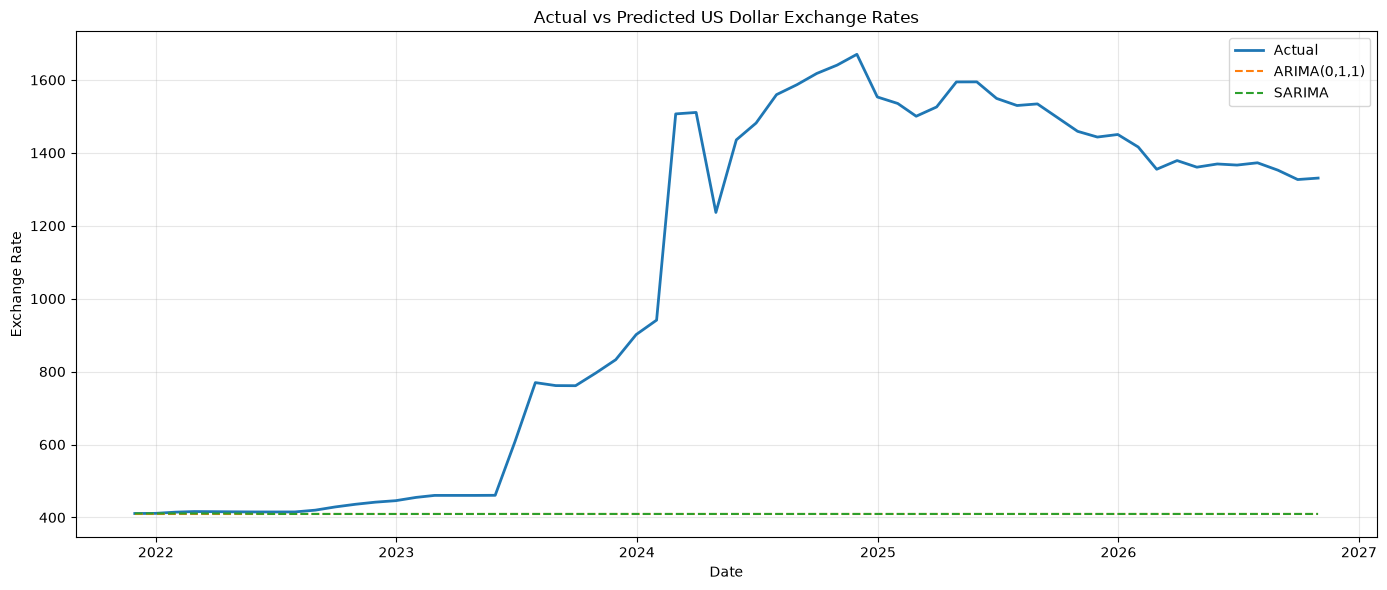

In [39]:
plt.figure(figsize=(14, 6))

plt.plot(test.index, test, label="Actual", linewidth=2)
plt.plot(test.index, arima_pred, label="ARIMA(0,1,1)", linestyle="--")
plt.plot(test.index, sarima_pred, label="SARIMA", linestyle="--")

plt.title("Actual vs Predicted US Dollar Exchange Rates")
plt.xlabel("Date")
plt.ylabel("Exchange Rate")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Interpretation of Actual and Predicted Exchange Rates

The plot shows that the actual US dollar exchange rate increased sharply during 2023 and 2024, while the ARIMA and SARIMA predictions remained relatively flat and failed to capture these major movements.

Both models struggled to represent the structural changes in the exchange rate during the test period. This is consistent with their high RMSE and MAE values. Although ARIMA performed slightly better than SARIMA on both metrics, the difference was small, and neither model captured the observed exchange-rate movements adequately.

These results suggest that the selected models have limited predictive performance over the test period, particularly when faced with substantial changes that were not present in the training data.

## 7 Walk-Forward Evaluation

The previous evaluation generated all 60 test-period predictions from a model fitted through October 2021. In this experiment, we will predict one month at a time, adding each actual observation to the available history before predicting the next month. This allows us to assess one-step-ahead forecasting performance separately from the previous 60-month forecast.

In [40]:
# Predict each month using the previous month's actual rate
naive_walk_forward = test.index.to_series().map(
    lambda date: usd_monthly.loc[usd_monthly.index < date].iloc[-1]
)

naive_walk_rmse = np.sqrt(mean_squared_error(test, naive_walk_forward))
naive_walk_mae = mean_absolute_error(test, naive_walk_forward)

print("Walk-forward naive RMSE:", round(naive_walk_rmse, 2))
print("Walk-forward naive MAE:", round(naive_walk_mae, 2))

Walk-forward naive RMSE: 94.55
Walk-forward naive MAE: 41.07


## 7.1 Walk-Forward ARIMA Evaluation

We will evaluate ARIMA(0,1,1) using one-step-ahead predictions. The model will be fitted to the available log-transformed historical data at each step, and its prediction will be converted back to the original exchange-rate scale. This allows us to compare ARIMA with the walk-forward naive baseline using the same test observations.

In [41]:
# Generate one-step-ahead ARIMA predictions
arima_walk_forward = []

log_history = log_train.copy()

for date in log_test.index:
    model = ARIMA(log_history, order=(0, 1, 1)).fit()
    log_prediction = model.forecast(steps=1).iloc[0]

    arima_walk_forward.append(np.exp(log_prediction))

    # Add the actual observation before predicting the next month
    log_history.loc[date] = log_test.loc[date]

arima_walk_forward = pd.Series(
    arima_walk_forward,
    index=test.index
)

# Evaluate ARIMA predictions
arima_walk_rmse = np.sqrt(
    mean_squared_error(test, arima_walk_forward)
)
arima_walk_mae = mean_absolute_error(
    test, arima_walk_forward
)

print("Walk-forward ARIMA RMSE:", round(arima_walk_rmse, 2))
print("Walk-forward ARIMA MAE:", round(arima_walk_mae, 2))

c:\Users\user\miniforge3\envs\streamlit-env\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


Walk-forward ARIMA RMSE: 120.7
Walk-forward ARIMA MAE: 50.23


## 7.2 Walk-Forward SARIMA Evaluation

We will evaluate the selected SARIMA(0,1,1)(1,0,0,12) model using one-step-ahead predictions. At each step, the model will use the available historical observations to predict the next month, then incorporate that month’s actual value before predicting the following month. We will calculate RMSE and MAE to compare its performance with the naive baseline and ARIMA.

In [42]:
# Generate one-step-ahead SARIMA predictions
sarima_walk_forward = []

log_history = log_train.copy()

for date in log_test.index:
    model = ARIMA(
        log_history,
        order=(0, 1, 1),
        seasonal_order=(1, 0, 0, 12)
    ).fit()

    log_prediction = model.forecast(steps=1).iloc[0]
    sarima_walk_forward.append(np.exp(log_prediction))

    # Add the actual observation before predicting the next month
    log_history.loc[date] = log_test.loc[date]

sarima_walk_forward = pd.Series(
    sarima_walk_forward,
    index=test.index
)

# Evaluate SARIMA predictions
sarima_walk_rmse = np.sqrt(
    mean_squared_error(test, sarima_walk_forward)
)
sarima_walk_mae = mean_absolute_error(
    test, sarima_walk_forward
)

print("Walk-forward SARIMA RMSE:", round(sarima_walk_rmse, 2))
print("Walk-forward SARIMA MAE:", round(sarima_walk_mae, 2))

c:\Users\user\miniforge3\envs\streamlit-env\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\user\miniforge3\envs\streamlit-env\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\user\miniforge3\envs\streamlit-env\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


Walk-forward SARIMA RMSE: 120.5
Walk-forward SARIMA MAE: 49.25


Interpretation

The walk-forward evaluation shows that the naive baseline achieved the lowest RMSE (94.55) and MAE (41.07), outperforming both ARIMA and SARIMA. SARIMA performed slightly better than ARIMA, with an RMSE of 120.50 and an MAE of 49.25, but neither model improved on the baseline.

This suggests that, for this dataset and evaluation period, using the most recently observed exchange rate was more accurate than the selected ARIMA and SARIMA models. The results also show why comparing forecasting models against a simple baseline is important.

## 7.3 Visualising Walk-Forward Predictions

We will compare the actual exchange rates with the one-step-ahead predictions from the naive baseline, ARIMA and SARIMA. This visual comparison will help us assess how closely each method follows the observed exchange-rate movements during the test period.

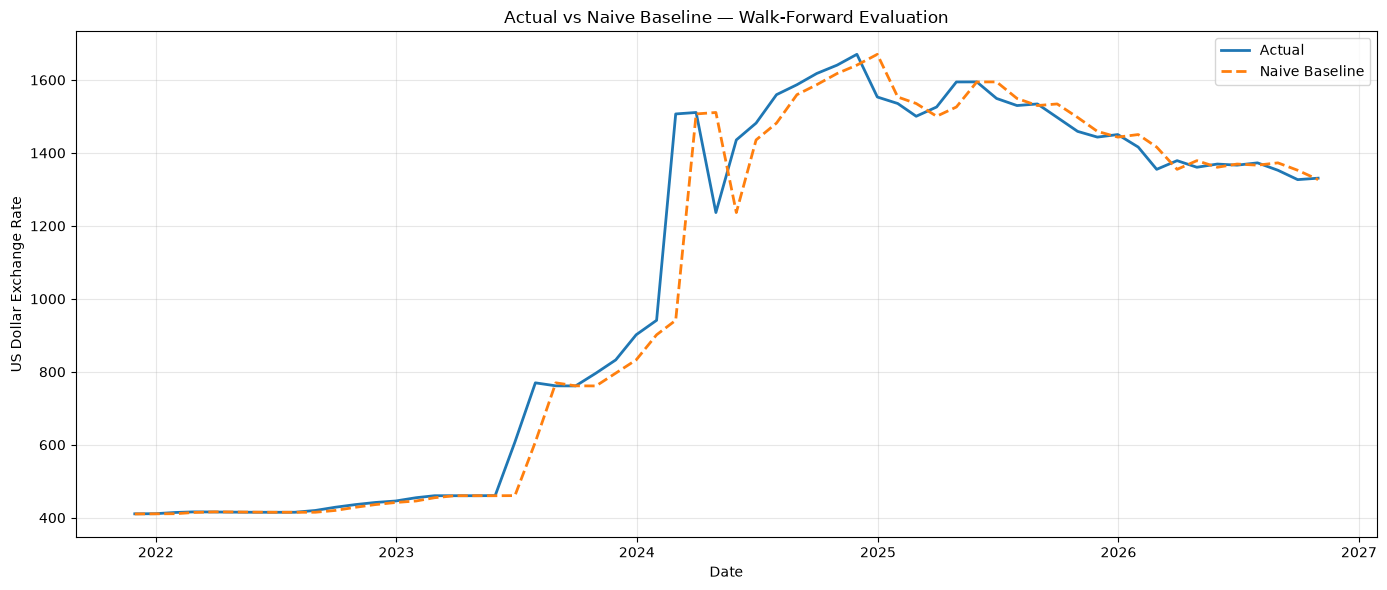

In [43]:
plt.figure(figsize=(14, 6))

plt.plot(test.index, test, label="Actual", linewidth=2)
plt.plot(
    test.index,
    naive_walk_forward,
    label="Naive Baseline",
    linestyle="--",
    linewidth=2
)

plt.title("Actual vs Naive Baseline — Walk-Forward Evaluation")
plt.xlabel("Date")
plt.ylabel("US Dollar Exchange Rate")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Interpretation 1: Actual vs Naive Baseline

The first graph compares the actual US dollar exchange rate with the naive baseline predictions, which use the most recently observed exchange rate to predict the following month.
The graph shows that the baseline follows the actual exchange rate quite closely across much of the test period. However, there are noticeable differences when the exchange rate changes sharply, particularly around 2023 and early 2024. The baseline reacts to these changes only after the new rate has been observed, so its predictions can lag behind sudden movements.

As the exchange rate begins to decline from its peak in 2025, the baseline generally follows the downward movement closely.
Overall, the graph suggests that the naive baseline captures the exchange rate's recent movements reasonably well, although it cannot anticipate sudden changes. This is consistent with its walk-forward evaluation results, where it achieved an RMSE of 94.55 and an MAE of 41.07.

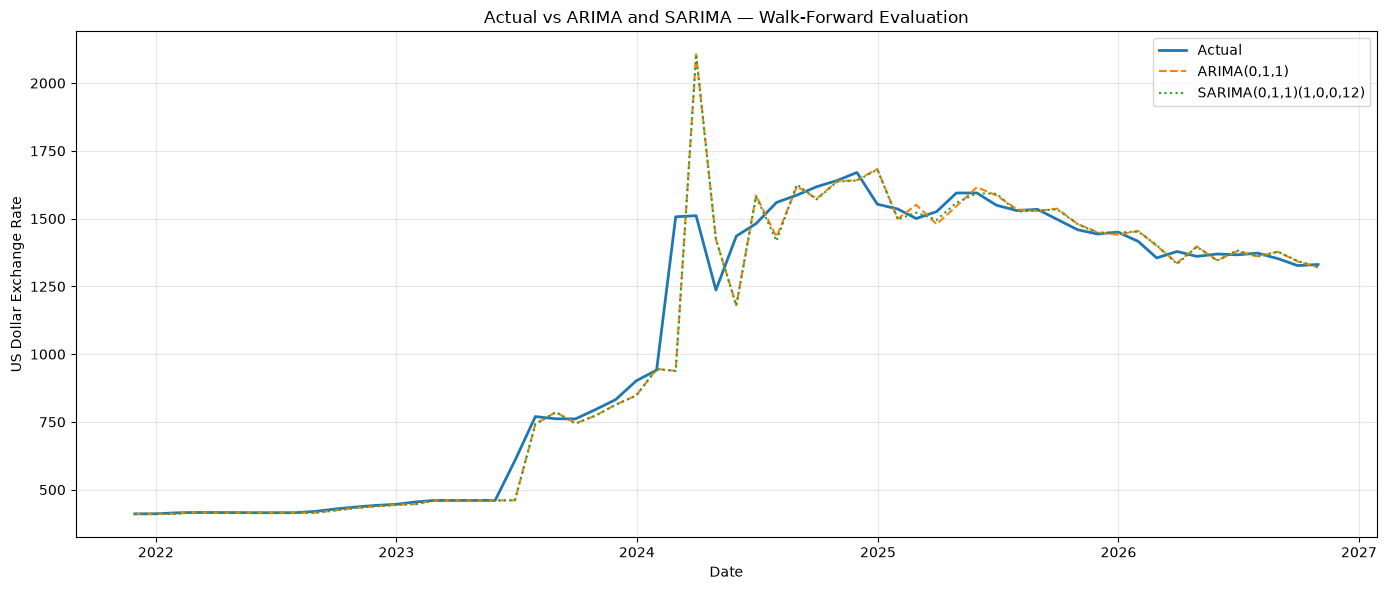

In [44]:
plt.figure(figsize=(14, 6))

plt.plot(test.index, test, label="Actual", linewidth=2)
plt.plot(
    test.index,
    arima_walk_forward,
    label="ARIMA(0,1,1)",
    linestyle="--",
    linewidth=1.5
)
plt.plot(
    test.index,
    sarima_walk_forward,
    label="SARIMA(0,1,1)(1,0,0,12)",
    linestyle=":",
    linewidth=1.5
)

plt.title("Actual vs ARIMA and SARIMA — Walk-Forward Evaluation")
plt.xlabel("Date")
plt.ylabel("US Dollar Exchange Rate")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Interpretation 2: Actual vs ARIMA and SARIMA

The second graph compares the actual exchange rate with predictions from ARIMA and SARIMA.
Both models capture some of the general movements in the exchange rate, particularly during periods when changes are more gradual. However, their predictions become less accurate around sharp fluctuations.
For example, around 2024, the ARIMA predictions show a pronounced spike that rises above the actual rate, followed by a sharp decline. SARIMA also deviates from the actual values during this period, although its predictions differ slightly from those of ARIMA.
As the exchange rate declines through 2025 and 2026, both models follow the general downward direction more closely. Nevertheless, their predictions do not consistently match the actual values.

The evaluation metrics support these observations:
ARIMA: RMSE = 120.70; MAE = 50.23.
SARIMA: RMSE = 120.50; MAE = 49.25.
SARIMA performs slightly better than ARIMA because it has lower RMSE and MAE values. However, both models perform worse than the naive baseline on this test period.

## 7.4 Comparing Forecasting Performance

We compare the naive baseline, ARIMA, and SARIMA using RMSE and MAE under two approaches:

Fixed-origin: Each model forecasts the full 60-month test set using only the training data.

Walk-forward: Each model forecasts one month ahead, then updates with the actual value before forecasting the next month.

Lower RMSE and MAE indicate better accuracy. Since the two approaches reflect different forecasting contexts, models should be compared within each approach, not across all six results.

In [45]:
# Compare existing results, identifying which models used log-transformed data.
# Fixed-origin and walk-forward results evaluate different forecasting approaches.

evaluation_comparison = pd.DataFrame([
    ["Fixed-origin (unlogged)", "Ordinary Naive",
     baseline_rmse, baseline_mae],
    ["Fixed-origin (unlogged)", "Seasonal Naive",
     seasonal_naive_rmse, seasonal_naive_mae],
    ["Fixed-origin (unlogged)", "ARIMA(1,1,1)",
     arima_111_rmse, arima_111_mae],

    ["Fixed-origin (log-transformed)", "ARIMA(0,1,1)",
     arima_rmse, arima_mae],
    ["Fixed-origin (log-transformed)", "SARIMA(0,1,1)(1,0,0,12)",
     sarima_rmse, sarima_mae],

    ["Walk-forward(unlogged)", "Ordinary Naive",
     naive_walk_rmse, naive_walk_mae],
    ["Walk-forward (log-transformed)", "ARIMA(0,1,1)",
     arima_walk_rmse, arima_walk_mae],
    ["Walk-forward (log-transformed)", "SARIMA(0,1,1)(1,0,0,12)",
     sarima_walk_rmse, sarima_walk_mae]
], columns=["Evaluation Method", "Model", "RMSE", "MAE"])

display(evaluation_comparison.round(2))

,Evaluation Method,Model,RMSE,MAE
0,Fixed-origin (unlogged),Ordinary Naive,805.90,643.17
1,Fixed-origin (unlogged),Seasonal Naive,818.45,659.96
2,Fixed-origin (unlogged),"ARIMA(1,1,1)",805.59,642.78
3,Fixed-origin (log-transformed),"ARIMA(0,1,1)",805.81,643.06
4,Fixed-origin (log-transformed),"SARIMA(0,1,1)(1,0,0,12)",806.56,643.88
5,Walk-forward(unlogged),Ordinary Naive,94.55,41.07
6,Walk-forward (log-transformed),"ARIMA(0,1,1)",120.70,50.23
7,Walk-forward (log-transformed),"SARIMA(0,1,1)(1,0,0,12)",120.50,49.25


## 7.5 Model Evaluation Comparison

The models were evaluated using Root Mean Squared Error (RMSE) and Mean Absolute Error (MAE). Lower values indicate smaller forecast errors.

Two evaluation approaches were used. Fixed-origin evaluation generates forecasts from the training period without incorporating actual test observations as they become available. Walk-forward evaluation generates one-step-ahead forecasts, updating the information available to the model as each actual observation is observed.

The fixed-origin results show that ARIMA(1,1,1) had the lowest RMSE and MAE among the fixed-origin models listed, although its performance was very close to the ordinary naive baseline. The seasonal naive model performed worse.

In the walk-forward evaluation, the ordinary naive baseline achieved the lowest RMSE and MAE. SARIMA performed slightly better than ARIMA, but neither model outperformed the naive baseline.

These results suggest that the more complex models did not consistently improve forecast accuracy for this exchange-rate series. The evaluation method matters, so results from fixed-origin and walk-forward forecasting should be interpreted separately rather than compared as if they were identical experiments.

## 7.6 Residual Diagnostics

Residual diagnostics help determine whether the fitted ARIMA model has captured the main patterns in the training data. Ideally, residuals should fluctuate around zero without a clear trend or systematic pattern.

We will examine the residual time series, their distribution, and their autocorrelation. We will also use the Ljung–Box test to check whether the residuals contain statistically significant autocorrelation. These checks help assess model adequacy, although they do not guarantee accurate forecasts.

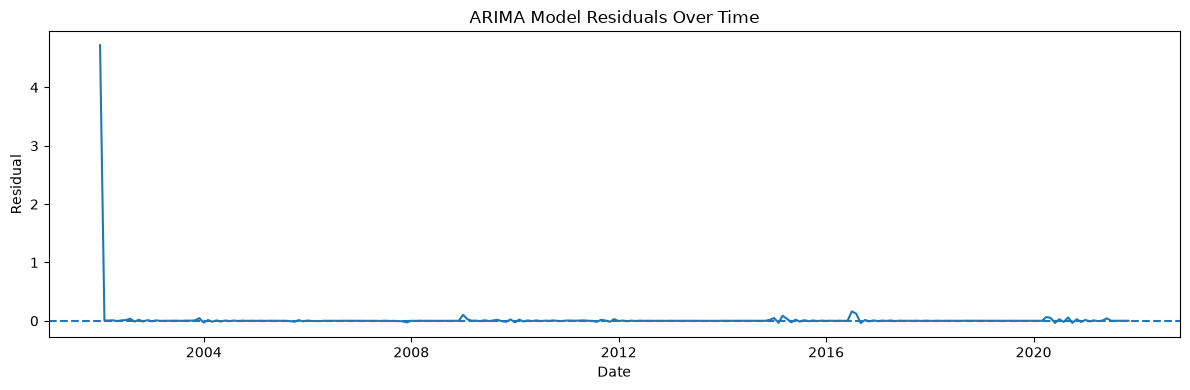

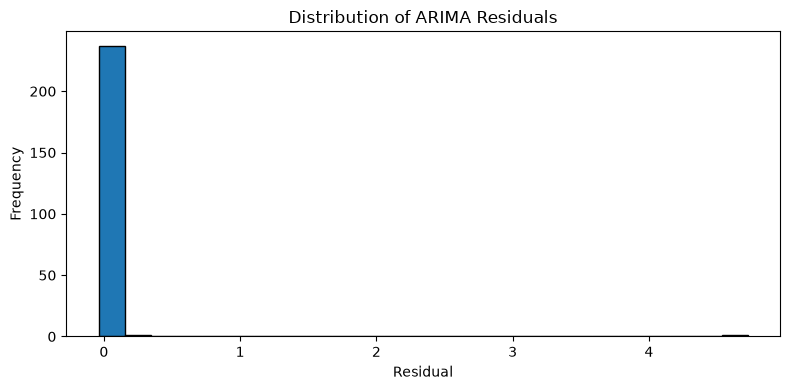

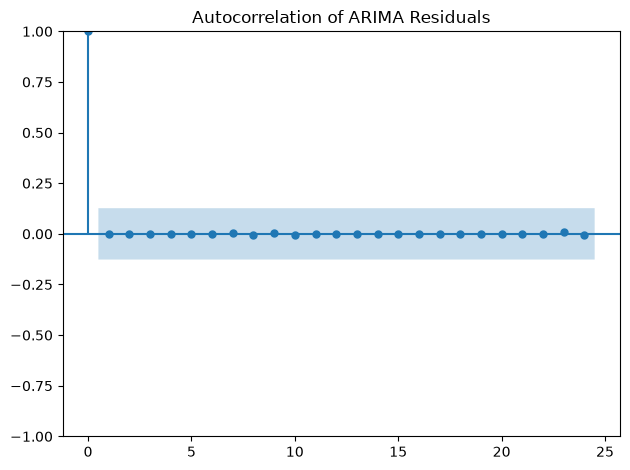

,lb_stat,lb_pvalue
12,2.704781,0.997294
24,16.278921,0.877746


In [46]:
# Residual diagnostics for the existing log-transformed ARIMA model

from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox
import matplotlib.pyplot as plt

# Extract residuals from the fitted model
residuals = arima_model.resid.dropna()

# 1. Plot residuals over time
plt.figure(figsize=(12, 4))
plt.plot(residuals.index, residuals)
plt.axhline(0, linestyle="--")
plt.title("ARIMA Model Residuals Over Time")
plt.xlabel("Date")
plt.ylabel("Residual")
plt.tight_layout()
plt.show()

# 2. Examine the distribution of residuals
plt.figure(figsize=(8, 4))
plt.hist(residuals, bins=25, edgecolor="black")
plt.title("Distribution of ARIMA Residuals")
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# 3. Check residual autocorrelation
plot_acf(residuals, lags=24)
plt.title("Autocorrelation of ARIMA Residuals")
plt.tight_layout()
plt.show()

# Exclude the initial residual and check for autocorrelation
residuals = arima_model.resid.iloc[1:].dropna()

ljung_box_results = acorr_ljungbox(
    residuals,
    lags=[12, 24],
    return_df=True
)

display(ljung_box_results)

 

Interpretation of Residual Diagnostics

The residual time-series plot shows a large positive residual at the start of the sample, with subsequent residuals clustered near zero. The histogram shows a right-skewed distribution driven by this initial residual.

The ACF plot shows no substantial autocorrelation within the confidence bounds. After excluding the initial residual, the Ljung-Box test gave p-values of approximately 0.9973 at lag 12 and 0.8777 at lag 24. Both exceed the 5% level, so we fail to reject the null of no autocorrelation at these lags.

Overall, there is no significant evidence of residual autocorrelation. However, the large initial residual and skewed distribution indicate the presence of an unusual observation. Results should therefore be interpreted alongside forecast errors and the model's limitation in capturing large exchange-rate shifts.

## 

## 7.7 Forecasting with the Ordinary Naive Baseline

The ordinary naive baseline performed best in the walk-forward evaluation, achieving the lowest RMSE and MAE among the evaluated models. Therefore, we examine its behaviour when forecasting beyond the observed data.

The ordinary naive method predicts that the next exchange rate will equal the most recently observed exchange rate. In walk-forward evaluation, each prediction uses the latest actual observation available at that point. However, when forecasting multiple future months, actual observations are unavailable, so the forecast remains at the last observed value.



,Forecast
2026-11-30,1330.79
2026-12-31,1330.79
2027-01-31,1330.79
2027-02-28,1330.79
2027-03-31,1330.79
2027-04-30,1330.79
2027-05-31,1330.79
2027-06-30,1330.79
2027-07-31,1330.79
2027-08-31,1330.79


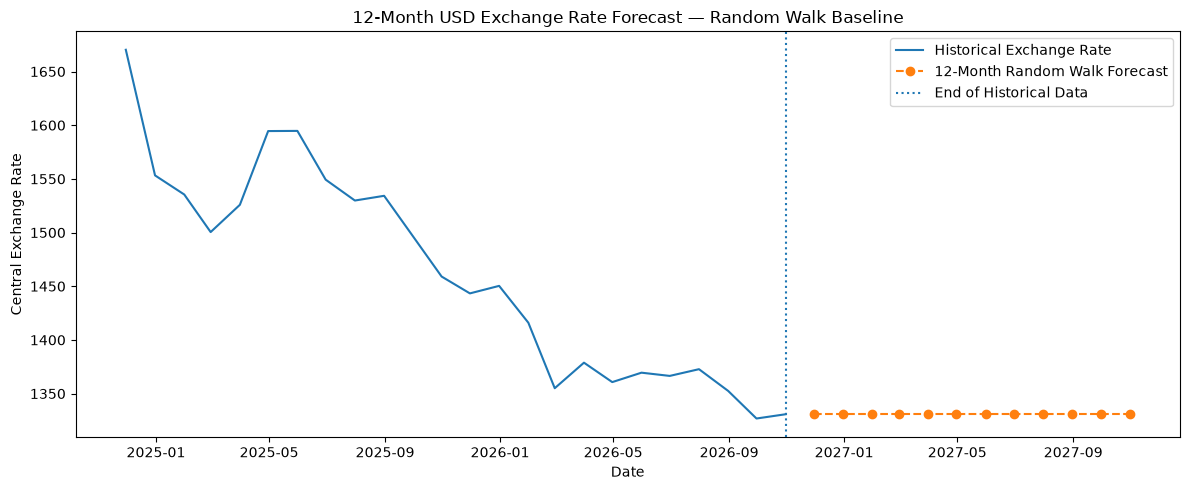

In [47]:
# Final 12-month forecast using the selected ordinary naive baseline

# Get the latest available monthly exchange rate
last_observed_rate = usd_monthly.iloc[-1]
last_observed_date = usd_monthly.index[-1]

# Generate the next 12 month-end dates
forecast_dates = pd.date_range(
    start=last_observed_date + pd.offsets.MonthEnd(1),
    periods=12,
    freq="ME"
)

# Random walk without drift: every forecast equals the latest observation
final_forecast = pd.Series(
    last_observed_rate,
    index=forecast_dates,
    name="Forecast"
)

# Display the forecast table
display(final_forecast.to_frame().round(2))

# Plot the last 24 historical monthly observations and the forecast
plt.figure(figsize=(12, 5))

plt.plot(
    usd_monthly.index[-24:],
    usd_monthly.iloc[-24:],
    label="Historical Exchange Rate"
)

plt.plot(
    final_forecast.index,
    final_forecast,
    linestyle="--",
    marker="o",
    label="12-Month Random Walk Forecast"
)

plt.axvline(
    last_observed_date,
    linestyle=":",
    label="End of Historical Data"
)

plt.title("12-Month USD Exchange Rate Forecast — Random Walk Baseline")
plt.xlabel("Date")
plt.ylabel("Central Exchange Rate")
plt.legend()
plt.tight_layout()
plt.show()

Interpretation of the 12-Month Forecast

The ordinary naive baseline was used to forecast the USD central exchange rate for the next 12 months. The forecast remains constant at approximately ₦1,330.79 because the method uses the last observed exchange rate as the prediction for every future period.

The historical series shows substantial fluctuations, including a decline during 2025 and 2026. However, the baseline does not capture future trends or sudden changes; it simply provides a reference forecast against which more advanced models can be evaluated. Therefore, this forecast should not be interpreted as a prediction that the exchange rate will remain unchanged. It demonstrates the limitations of a simple baseline when applied to a volatile exchange-rate series.


## 7.8 ARIMA Forecast with a 95% Prediction Interval

To complement the ordinary naive baseline, an ARIMA model is fitted to the full historical log-transformed exchange-rate series to generate a 12-month forecast. A 95% prediction interval is included to illustrate the uncertainty surrounding the model’s future predictions.

The ARIMA forecast provides a model-based alternative to the constant naive forecast. However, its historical test-period performance and the substantial structural changes in the exchange rate must be considered when interpreting the results.

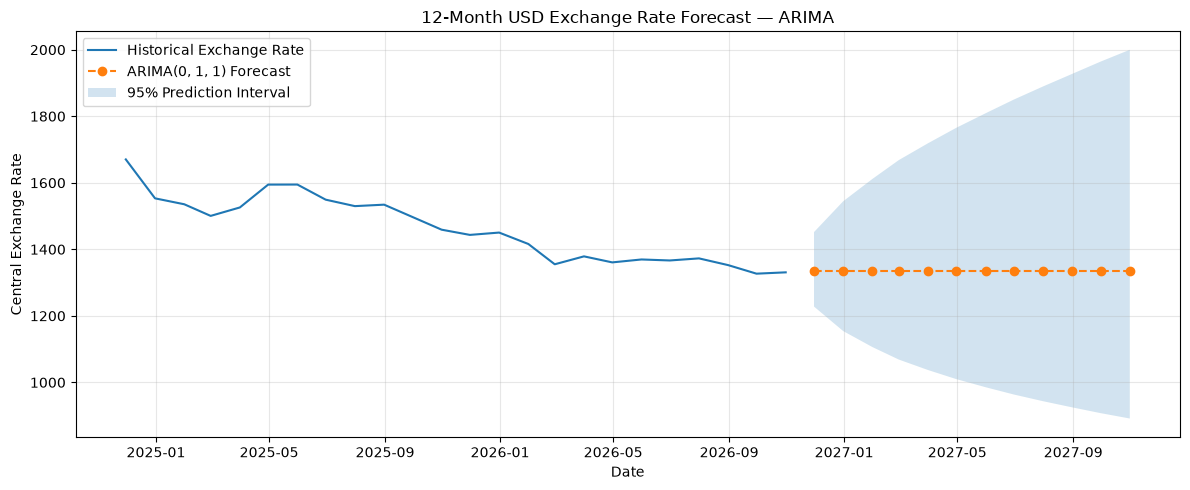

In [48]:
# Fit ARIMA(0, 1, 1) to the full historical log-transformed series
final_arima_model = ARIMA(
    np.log(usd_monthly),
    order=(0, 1, 1)
).fit()

# Forecast the next 12 months
forecast_result = final_arima_model.get_forecast(steps=12)

# Convert predictions and 95% prediction intervals to the original scale
forecast_mean = np.exp(forecast_result.predicted_mean)
forecast_ci = np.exp(forecast_result.conf_int())

# Plot recent history and the forecast
plt.figure(figsize=(12, 5))

plt.plot(
    usd_monthly.index[-24:],
    usd_monthly.iloc[-24:],
    label="Historical Exchange Rate"
)

plt.plot(
    forecast_mean.index,
    forecast_mean,
    "--o",
    label="ARIMA(0, 1, 1) Forecast"
)

plt.fill_between(
    forecast_ci.index,
    forecast_ci.iloc[:, 0],
    forecast_ci.iloc[:, 1],
    alpha=0.2,
    label="95% Prediction Interval"
)

plt.title("12-Month USD Exchange Rate Forecast — ARIMA")
plt.xlabel("Date")
plt.ylabel("Central Exchange Rate")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Interpretation of the 12-Month ARIMA Forecast

The log-transformed ARIMA(0, 1, 1) model was fitted to the full historical monthly exchange-rate series to forecast the next 12 months. The forecast indicates a gradual decline in the USD central exchange rate from its latest observed level. The 95% prediction interval widens over the forecast horizon, indicating increasing uncertainty around the predicted values.

Although the model provides a useful representation of the expected exchange-rate path under its estimated historical patterns, the forecast should be interpreted cautiously. The interval is wide, and the historical series contains substantial structural changes that the model may not anticipate. The forecast therefore illustrates a possible model-based trajectory rather than a guarantee of future exchange-rate movements.

# 8. Conclusion

This project analysed the monthly USD central exchange rate using data obtained from the Central Bank of Nigeria (CBN). The data was prepared by filtering USD observations, resolving duplicate dates through averaging, and aggregating daily observations into monthly averages.

Exploratory analysis and time-series decomposition revealed a strong upward long-term trend, relatively weak annual seasonality, and substantial fluctuations associated with structural changes in the exchange rate. The Augmented Dickey–Fuller (ADF) test indicated that the log-transformed series was non-stationary, while its first difference was stationary, supporting the use of first differencing in the ARIMA-based models.

Moving averages and exponential smoothing were used to examine the underlying trend and smooth short-term fluctuations. ARIMA and SARIMA models were subsequently developed and evaluated using RMSE and MAE. Their fixed-origin forecasts did not adequately capture the sharp exchange-rate movements observed during the test period. In the walk-forward evaluation, the ordinary naive baseline achieved lower errors than the ARIMA and SARIMA models.

Residual diagnostics for the log-transformed ARIMA model showed no significant evidence of residual autocorrelation at the tested lags after excluding the initial residual from the Ljung–Box test. However, the unusually large initial residual and the skewed residual distribution indicate that some aspects of the series remain insufficiently captured by the model.

For the 12-month future forecast, the ordinary naive baseline was retained as a simple reference because of its performance in the walk-forward evaluation. A separate ARIMA(0, 1, 1) model was also fitted to the full historical log-transformed series to produce a 12-month forecast with a 95% prediction interval. The ARIMA forecast projected a gradual decline, while its widening prediction interval illustrated increasing uncertainty over the forecast horizon. Neither forecast should be interpreted as a guarantee of future exchange-rate movements.

Overall, this project demonstrates the importance of comparing forecasting models with a simple baseline, evaluating performance on unseen data, examining residuals, and communicating forecast uncertainty. Future work could explore additional economic variables, alternative forecasting approaches, and updated observations to improve predictive performance, particularly when substantial exchange-rate changes occur.